# import package

In [1]:
from google.colab import drive
drive.mount('/content/drive/')



Mounted at /content/drive/


In [2]:
import sys
#sys.path.append('/content/drive/MyDrive/Research/0-Xiayin_research/4_GeoCP_with_geosimilarity/GeoConformal')
sys.path.append('/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/GeoConformal')

import GeoConformalSpatialRegression

In [3]:
!pip install libpysal esda

In [4]:
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from esda.moran import Moran
from scipy.ndimage import gaussian_filter
from scipy.stats import multivariate_normal
from sklearn.model_selection import train_test_split

# data generation

In [5]:
def compute_moran(data, grid_size=100):
    w = libpysal.weights.lat2W(grid_size, grid_size)
    w.transform = 'r'  # Row-standardization
    moran = Moran(data, w)
    return moran.I

In [6]:
# Generate a random 50x50 grid
np.random.seed(42)
grid_size = 100
data = np.random.rand(grid_size, grid_size)  # Random values

In [7]:
smooth_data = gaussian_filter(np.random.uniform(0, 6, size=(grid_size, grid_size)), sigma=0.6)
smooth_data_flat = smooth_data.flatten()
base_values = np.random.uniform(10, 20, size=(grid_size, grid_size))

In [8]:
def true_model_predict(X_features):
    """
    真实模型：目标变量是 X1 + X2。
    假设 X_features 的第 0 列是 X1，第 1 列是 X2。
    """
    return X_features[:, 0] + X_features[:, 1]




In [9]:
def biased_model_predict(X_features, noise):
    """
    偏置模型：在真实模型的基础上加上噪声（1D 向量）。
    """
    y_true = true_model_predict(X_features)
    return y_true + noise


In [10]:
# 基础数据
grid_size = 100
x = np.linspace(0, 1, grid_size)
y = np.linspace(0, 1, grid_size)
X_grid, Y_grid = np.meshgrid(x, y)
coords = np.stack([X_grid.ravel(), Y_grid.ravel()], axis=1)
X_coords = pd.DataFrame(coords, columns=["x_coord", "y_coord"])

np.random.seed(42)
X1 = gaussian_filter(np.random.uniform(5, 10, size=(grid_size, grid_size)), sigma=5).flatten()
X2 = gaussian_filter(np.random.uniform(0, 6, size=(grid_size, grid_size)), sigma=1.5).flatten()

true_y = X1 + X2
noise = np.random.normal(0, 1, size=true_y.shape)

df_coord_to_feat = X_coords.copy()
df_coord_to_feat["X1"] = X1
df_coord_to_feat["X2"] = X2

df_coord_to_noise = X_coords.copy()
df_coord_to_noise["noise"] = noise

# 拆分
X_spatial_train, X_spatial_temp, X_aspatial_train, X_aspatial_temp, y_train, y_temp, loc_train, loc_temp = train_test_split(
    X_coords, np.vstack([X1, X2]).T, true_y, X_coords, train_size=0.8, random_state=42
)
X_spatial_val, X_spatial_test, X_aspatial_val, X_aspatial_test, y_val, y_test, loc_val, loc_test = train_test_split(
    X_spatial_temp, X_aspatial_temp, y_temp, loc_temp, train_size=0.5, random_state=42
)

# GeoCP输入
X_calib = loc_val.copy()        # 只要 x_coord, y_coord
X_test = X_coords.copy()
y_calib = y_val
y_test = true_y
coord_calib = loc_val.values
coord_test = X_coords.values

# predict_f
predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)

print("✅ 全部准备就绪")

✅ 全部准备就绪


In [11]:
# 创建有空间模式的噪声
import numpy as np
from scipy.ndimage import gaussian_filter

def generate_spatial_noise(grid_size=100, noise_std=0.75, sigma=0.2, seed=None):
    """
    生成一个具有空间相关性的噪声场。

    参数说明：
    - grid_size: 空间格网的尺寸（默认100x100）
    - noise_std: 原始高斯噪声的标准差（控制强度）
    - sigma: 高斯滤波器的 sigma（控制空间平滑程度）
    - seed: 随机数种子（保证可重复性）

    返回：
    - noise_map: 1维 np.array，大小为 grid_size * grid_size
    - noise_grid: 2维 np.array，形状为 (grid_size, grid_size)
    """
    if seed is not None:
        np.random.seed(seed)

    base_noise = np.random.normal(loc=0, scale=noise_std, size=(grid_size, grid_size))
    smoothed_noise = gaussian_filter(base_noise, sigma=sigma)
    return smoothed_noise.flatten(), smoothed_noise
# def create_coord_noise_df(X_coords, grid_size=100, noise_std=0.75, sigma=3, seed=None):
#     """
#     根据坐标生成一个带有空间相关性噪声值的 DataFrame。

#     参数：
#     - X_coords: 包含 "x_coord", "y_coord" 的 DataFrame，大小应为 grid_size^2
#     - grid_size: 坐标格网大小（默认 100）
#     - noise_std: 高斯噪声标准差（控制噪声幅度）
#     - sigma: 高斯滤波平滑参数（控制空间相关性）
#     - seed: 随机数种子（可选）

#     返回：
#     - df_noise: DataFrame，包括 "x_coord", "y_coord", "noise"
#     """
#     # 生成空间噪声
#     noise_1d, _ = generate_spatial_noise(grid_size=grid_size, noise_std=noise_std, sigma=sigma, seed=seed)

#     # 构建包含噪声的 DataFrame
#     df_noise = X_coords.copy()
#     df_noise["noise"] = noise_1d

#     return df_noise

# def create_coord_noise_df(X_coords, grid_size=100, noise_std=1, sigma=3, seed=None,
#                            correlate_with_y=False, true_y=None, correlation_strength=0.5):
#     """
#     根据坐标生成一个带有空间相关性噪声值的 DataFrame。
#     - 支持生成与 true_y 有空间相关性的 noise
#     - 否则生成独立的 spatial noise

#     参数：
#     - X_coords: 包含 "x_coord", "y_coord" 的 DataFrame
#     - grid_size: 格网大小
#     - noise_std: 额外噪声幅度
#     - sigma: 高斯滤波平滑参数（仅在 correlate_with_y=False时有效）
#     - seed: 随机种子
#     - correlate_with_y: 是否让噪声和 true_y强相关
#     - true_y: 真实目标值（必须是1维数组，且和 X_coords对齐）
#     - correlation_strength: 控制 true_y 在 noise 中占比 (0~1)

#     返回：
#     - df_noise: DataFrame，含 "x_coord", "y_coord", "noise"
#     """
#     np.random.seed(seed)

#     if correlate_with_y:
#         if true_y is None:
#             raise ValueError("If correlate_with_y=True, true_y must be provided.")

#         # 构造：noise = a * true_y + Gaussian noise
#         noise = correlation_strength * true_y + np.random.normal(0, noise_std, size=true_y.shape)

#     else:
#         # 纯空间平滑的随机噪声
#         base_noise = np.random.normal(loc=0, scale=noise_std, size=(grid_size, grid_size))
#         noise = gaussian_filter(base_noise, sigma=sigma).flatten()

#     # 生成 DataFrame
#     df_noise = X_coords.copy()
#     df_noise["noise"] = noise

#     return df_noise


def create_coord_noise_df(X_coords, grid_size=100, noise_std=1, sigma=3, seed=None,
                           correlate_with_y=False, true_y=None, correlation_strength=0.5,
                           feature_space_cluster=False, X_features=None, cluster_center=(7, 2), cluster_width=0.5):
    """
    根据坐标生成一个带有噪声的 DataFrame。
    - 支持三种模式：
      1. 传统地理空间生成（默认）
      2. true_y空间相关生成
      3. 特征空间(X1,X2)聚集生成

    参数：
    - X_coords: 包含 "x_coord", "y_coord" 的 DataFrame
    - grid_size: 网格大小
    - noise_std: 高斯噪声标准差
    - sigma: 地理空间高斯平滑参数
    - seed: 随机种子
    - correlate_with_y: 是否使噪声与true_y相关（优先级高）
    - true_y: 如果correlate_with_y为True，需要提供
    - correlation_strength: 与true_y的线性相关强度
    - feature_space_cluster: 是否在特征空间生成聚集噪声
    - X_features: (n_samples, 2)，特征空间 (X1,X2)，feature_space_cluster=True时需要
    - cluster_center: 特征空间中噪声高发区域中心 (X1_center, X2_center)
    - cluster_width: 控制高噪声区域大小
    """
    np.random.seed(seed)

    if correlate_with_y:
        if true_y is None:
            raise ValueError("If correlate_with_y=True, true_y must be provided.")

        noise = correlation_strength * true_y + np.random.normal(0, noise_std, size=true_y.shape)

    elif feature_space_cluster:
        if X_features is None:
            raise ValueError("If feature_space_cluster=True, X_features must be provided.")

        X1 = X_features[:, 0]
        X2 = X_features[:, 1]

        # 计算特征空间中到 cluster_center 的距离
        dist = np.sqrt((X1 - cluster_center[0])**2 + (X2 - cluster_center[1])**2)

        # 距离越小，噪声越强，形成局部聚集
        noise_strength = np.exp(-(dist**2) / (2 * cluster_width**2))

        noise = noise_strength * np.random.normal(0, noise_std, size=X1.shape)

        ##consider sigma
        noise_grid = noise.reshape(grid_size, grid_size)
        noise = gaussian_filter(noise_grid, sigma=sigma).flatten()


    else:
        # 默认地理空间生成：生成高斯噪声+空间平滑
        base_noise = np.random.normal(loc=0, scale=noise_std, size=(grid_size, grid_size))
        noise = gaussian_filter(base_noise, sigma=sigma).flatten()

    # 生成 DataFrame
    df_noise = X_coords.copy()
    df_noise["noise"] = noise

    return df_noise


def biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise):
    """
    输入:
    - X_df: 包含 x_coord 和 y_coord 的 DataFrame（测试集）
    - df_coord_to_feat: 包含 X1 和 X2 的完整特征表（x_coord, y_coord, X1, X2）
    - df_coord_to_noise: 包含空间噪声值的表（x_coord, y_coord, noise）

    输出:
    - biased prediction = (X1 + X2) + noise
    """
    merged = pd.merge(X_df, df_coord_to_feat, on=["x_coord", "y_coord"], how="left")
    merged = pd.merge(merged, df_coord_to_noise, on=["x_coord", "y_coord"], how="left")

    biased_pred = (merged["X1"] + merged["X2"]) + merged["noise"]
    return biased_pred.values

In [12]:
def compute_moran(data, grid_size=100):
    w = libpysal.weights.lat2W(grid_size, grid_size)
    w.transform = 'r'  # Row-standardization
    moran = Moran(data, w)
    return moran.I


In [13]:
## test
from GeoConformalSpatialRegression import GeoConformalSpatialRegression

noise_sigma=10
    # 1. 生成空间噪声
df_coord_to_noise = create_coord_noise_df(
    X_coords=X_coords,
    grid_size=100,
    noise_std=1,
    sigma=noise_sigma,
    seed=42
)

# 先建立一个 (坐标 ➝ X1, X2) 的查表方式：
df_coord_to_feat = X_coords.copy()
df_coord_to_feat["X1"] = X1
df_coord_to_feat["X2"] = X2

# 2. 定义 biased predict function
predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)


# 3. GeoCP模型
geocp_spatial_biased = GeoConformalSpatialRegression(
    predict_f=predict_f,
    miscoverage_level=0.1,
    bandwidth=0.1,
    coord_calib=coord_calib,
    coord_test=coord_test,
    X_calib=X_calib,
    y_calib=y_calib,
    X_test=X_test,
    y_test=y_test
)

results_biased = geocp_spatial_biased.analyze()
results_geo_biased = results_biased.to_gpd()

# 4. 提取结果（都从 results_geo_biased 里面取！✅）
geo_uncertainty = results_geo_biased["geo_uncertainty"].values.reshape(100, 100)
#y_pred = results_geo_biased["predicted_value"].values.reshape(100, 100)
y_pred = biased_model_predict(X_coords, df_coord_to_feat, df_coord_to_noise).reshape(100, 100)
noise_grid = df_coord_to_noise["noise"].values.reshape(100, 100)
true_y_grid = true_y.reshape(100, 100)
y_error = np.abs(true_y_grid - y_pred)
y_error =  y_pred-true_y_grid

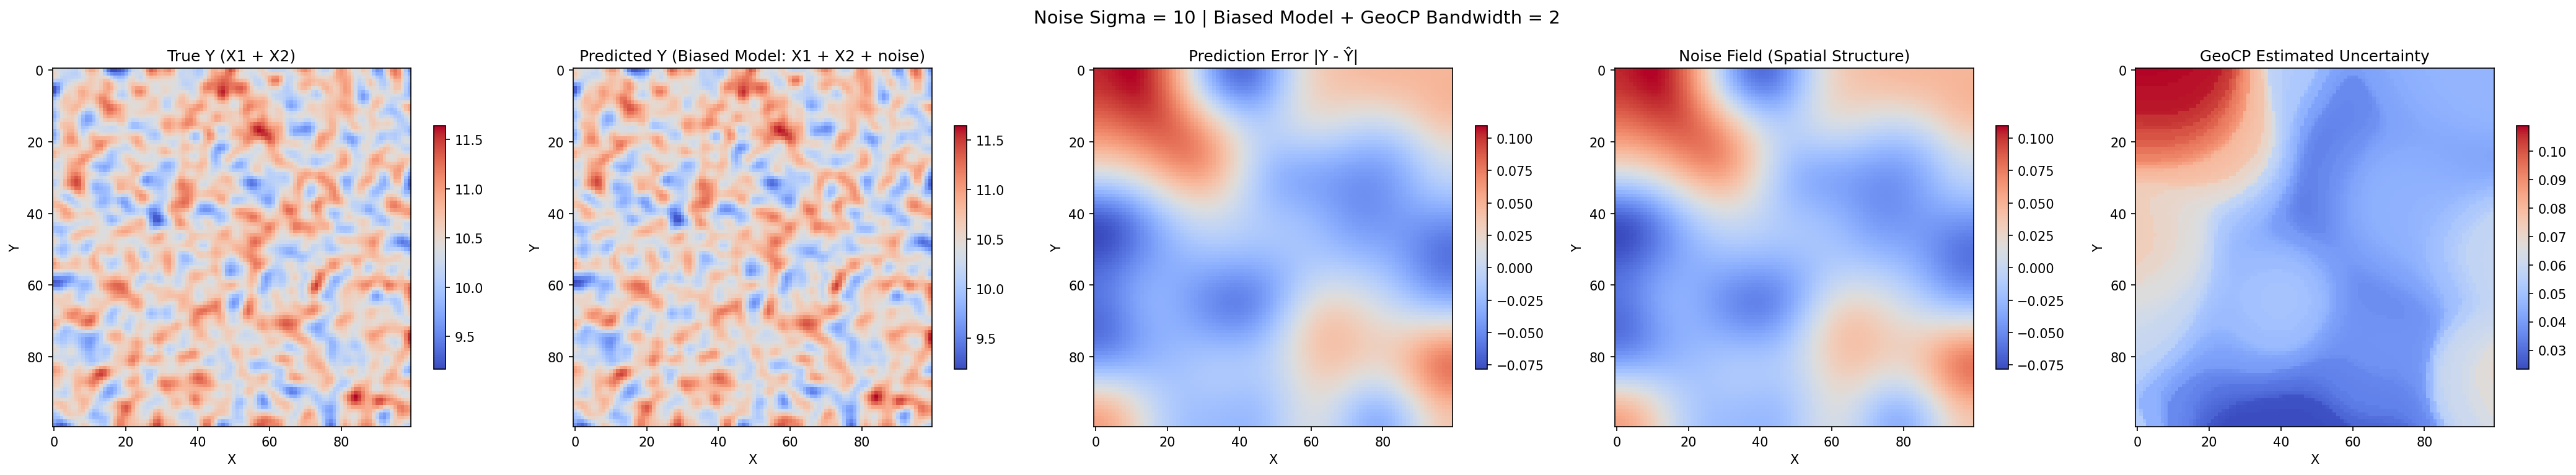

In [14]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 5, figsize=(28, 5), dpi=150)
ax1, ax2, ax3, ax4, ax5 = axes

# True Y
c1 = ax1.imshow(true_y_grid, cmap='coolwarm')
fig.colorbar(c1, ax=ax1, shrink=0.6)
ax1.set_title("True Y (X1 + X2)")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")

# Predicted Y
c2 = ax2.imshow(y_pred, cmap='coolwarm')
fig.colorbar(c2, ax=ax2, shrink=0.6)
ax2.set_title("Predicted Y (Biased Model: X1 + X2 + noise)")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")

# Prediction Error
c3 = ax3.imshow(y_error, cmap='coolwarm')
fig.colorbar(c3, ax=ax3, shrink=0.6)
ax3.set_title("Prediction Error |Y - Ŷ|")
ax3.set_xlabel("X")
ax3.set_ylabel("Y")

# Noise Field
c4 = ax4.imshow(noise_grid, cmap='coolwarm')
fig.colorbar(c4, ax=ax4, shrink=0.6)
ax4.set_title("Noise Field (Spatial Structure)")
ax4.set_xlabel("X")
ax4.set_ylabel("Y")

# GeoCP Uncertainty
c5 = ax5.imshow(geo_uncertainty, cmap='coolwarm')
fig.colorbar(c5, ax=ax5, shrink=0.6)
ax5.set_title("GeoCP Estimated Uncertainty")
ax5.set_xlabel("X")
ax5.set_ylabel("Y")

plt.suptitle(f"Noise Sigma = {noise_sigma} | Biased Model + GeoCP Bandwidth = 2", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
# 手动重算校准误差
y_calib_pred = predict_f(X_spatial_val)
nonconformity_scores = np.abs(y_calib_pred - y_val)

print("Nonconformity score (mean):", nonconformity_scores.mean())
print("Nonconformity score (std):", nonconformity_scores.std())

Nonconformity score (mean): 0.03189793248524951
Nonconformity score (std): 0.02209170971017823


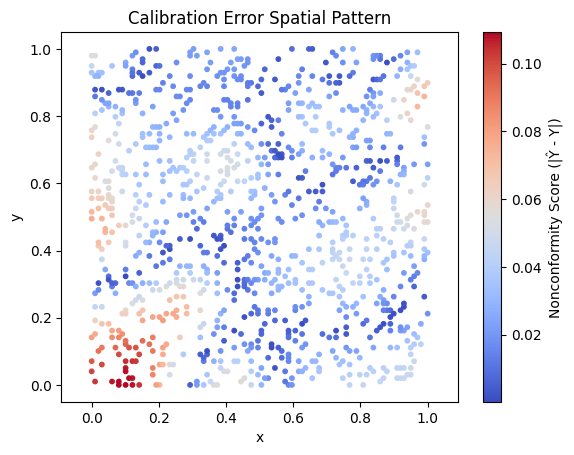

In [16]:
import matplotlib.pyplot as plt

error_val = np.abs(predict_f(X_spatial_val) - y_val)
plt.scatter(loc_val["x_coord"], loc_val["y_coord"], c=error_val, cmap="coolwarm", s=10)
plt.colorbar(label="Nonconformity Score (|Ŷ - Y|)")
plt.title("Calibration Error Spatial Pattern")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

In [19]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# ========= 关键：全局字体与 PDF 设置 =========
mpl.rcParams['pdf.fonttype'] = 42      # TrueType (Type 42) —— Illustrator 可识别
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial' # 或 'Helvetica', 'Times New Roman'
mpl.rcParams['text.usetex'] = False    # 防止 LaTeX 生成 Type 3 字体

# ========= 数据 =========
noise_flat = noise_grid.flatten()
error_flat = y_error.flatten()

# ========= 作图 =========
plt.figure(figsize=(6, 6))
plt.scatter(
    noise_flat,
    error_flat,
    s=5,
    alpha=0.5,
    c='teal'
)

plt.xlabel("Noise Value", fontsize=12)
plt.ylabel("Prediction Error |Y - Ŷ|", fontsize=12)
plt.title("Noise vs. Prediction Error", fontsize=13)
plt.grid(True, linewidth=0.5, alpha=0.6)

plt.tight_layout()

# ========= 导出 PDF =========
plt.savefig(
    "noise_vs_prediction_error.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.close()


# 测试

## 批量

In [ ]:
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
import numpy as np
import pandas as pd
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error
from skimage.metrics import structural_similarity
# -----------------------
# 设定噪声平滑参数列表
# -----------------------
noise_sigmas = [1, 2, 3, 4, 5, 6, 7, 8]
noise_sigmas=[0.1,0.5,1,1.5,2,2.5,3,5,10]
results_summary = []

for noise_sigma in noise_sigmas:
    print(f"Running GeoCP for noise_sigma = {noise_sigma}...")

    # 1. 生成新的空间噪声
    df_coord_to_noise = create_coord_noise_df(
        X_coords=X_coords,
        grid_size=100,
        noise_std=10,
        sigma=noise_sigma,
        seed=42
    )

    # 2. 重新定义 biased predict function（绑定新的 noise）
    predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)

    # 3. 重新建立 GeoCP 模型

    geocp_spatial_biased = GeoConformalSpatialRegression(
    predict_f=predict_f,
    miscoverage_level=0.1,
    bandwidth=0.1,
    coord_calib=coord_calib,
    coord_test=coord_test,
    X_calib=X_calib,
    y_calib=y_calib,
    X_test=X_test,
    y_test=y_test
)


    results_biased = geocp_spatial_biased.analyze()
    results_geo_biased = results_biased.to_gpd()

    # 4. 提取结果
    geo_uncertainty = results_geo_biased["geo_uncertainty"].values.reshape(100, 100)
    y_pred = biased_model_predict(X_coords, df_coord_to_feat, df_coord_to_noise).reshape(100, 100)
    noise_grid = df_coord_to_noise["noise"].values.reshape(100, 100)
    true_y_grid = true_y.reshape(100, 100)
    y_error = np.abs(true_y_grid - y_pred)

    # 5. 计算统计指标
    coverage_rate = results_biased.coverage_probability
    noise_moran_i = compute_moran(noise_grid)
    data_moran_i = compute_moran(true_y_grid)
    rmse = root_mean_squared_error(np.abs(noise_grid), geo_uncertainty)
    corr = np.corrcoef(np.abs(noise_grid).flatten(), geo_uncertainty.flatten())[0, 1]
    ssim = structural_similarity(
        np.abs(noise_grid),
        geo_uncertainty,
        data_range=np.ptp(np.abs(noise_grid))
    )

    # 保存当前结果
    results_summary.append({
        "noise_sigma": noise_sigma,
        "rmse": rmse,
        "corr": corr,
        "ssim": ssim,
        "noise_moran": noise_moran_i,
        "data_moran": data_moran_i,
        "coverage_rate": coverage_rate
    })

    # 6. 可视化（2行3列子图）
    fig, axes = plt.subplots(2, 3, figsize=(18, 8), dpi=300)
    ax1, ax2, ax3, ax4, ax5, ax6 = axes.ravel()

    # True Y
    c1 = ax1.imshow(true_y_grid, cmap='coolwarm')
    fig.colorbar(c1, ax=ax1, shrink=0.5)
    ax1.set_title('True Y')

    # Predicted Y
    c2 = ax2.imshow(y_pred, cmap='coolwarm')
    fig.colorbar(c2, ax=ax2, shrink=0.5)
    ax2.set_title('Predicted Y (Biased Model)')

    # Prediction Error
    c3 = ax3.imshow(y_error, cmap='coolwarm')
    fig.colorbar(c3, ax=ax3, shrink=0.5)
    ax3.set_title('Prediction Error |Y - Ŷ|')

    # GeoCP Uncertainty
    c4 = ax4.imshow(geo_uncertainty, cmap='coolwarm')
    fig.colorbar(c4, ax=ax4, shrink=0.5)
    ax4.set_title('GeoCP Uncertainty')

    # Noise Field
    c5 = ax5.imshow(noise_grid, cmap='coolwarm')
    fig.colorbar(c5, ax=ax5, shrink=0.5)
    ax5.set_title('Noise Field')

    # Absolute Noise
    c6 = ax6.imshow(np.abs(noise_grid), cmap='coolwarm')
    fig.colorbar(c6, ax=ax6, shrink=0.5)
    ax6.set_title('Abs(Noise)')

    fig.suptitle(
        f'Noise Sigma={noise_sigma}, RMSE={rmse:.4f}, Corr={corr:.4f}, SSIM={ssim:.4f}, '
        f'Data Moran={data_moran_i:.4f}, Noise Moran={noise_moran_i:.4f}, Coverage={coverage_rate:.4f}',
        fontsize=12
    )
    plt.tight_layout()
    plt.show()
    plt.close()

# 7. 保存所有统计指标
results_df = pd.DataFrame(results_summary)
results_df.to_csv("geoCP_biased_model_results.csv", index=False)

print("✅ All experiments completed and results saved.")

Output hidden; open in https://colab.research.google.com to view.

## GeoSIMcp test


In [ ]:
# 基础数据
grid_size = 100
x = np.linspace(0, 1, grid_size)
y = np.linspace(0, 1, grid_size)
X_grid, Y_grid = np.meshgrid(x, y)
coords = np.stack([X_grid.ravel(), Y_grid.ravel()], axis=1)
X_coords = pd.DataFrame(coords, columns=["x_coord", "y_coord"])

np.random.seed(42)
X1 = gaussian_filter(np.random.uniform(5, 10, size=(grid_size, grid_size)), sigma=5).flatten()
X2 = gaussian_filter(np.random.uniform(0, 6, size=(grid_size, grid_size)), sigma=1.5).flatten()

true_y = X1 + X2
noise = np.random.normal(0, 1, size=true_y.shape)

df_coord_to_feat = X_coords.copy()
df_coord_to_feat["X1"] = X1
df_coord_to_feat["X2"] = X2

df_coord_to_noise = X_coords.copy()
df_coord_to_noise["noise"] = noise

# 拆分
X_spatial_train, X_spatial_temp, X_aspatial_train, X_aspatial_temp, y_train, y_temp, loc_train, loc_temp = train_test_split(
    X_coords, np.vstack([X1, X2]).T, true_y, X_coords, train_size=0.8, random_state=42
)
X_spatial_val, X_spatial_test, X_aspatial_val, X_aspatial_test, y_val, y_test, loc_val, loc_test = train_test_split(
    X_spatial_temp, X_aspatial_temp, y_temp, loc_temp, train_size=0.5, random_state=42
)

# GeoCP输入
X_calib = loc_val.copy()        # 只要 x_coord, y_coord
X_test = X_coords.copy()
y_calib = y_val
y_test = true_y
coord_calib = loc_val.values
coord_test = X_coords.values

# predict_f
predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)

print("✅ 全部准备就绪")

✅ 全部准备就绪


Output hidden; open in https://colab.research.google.com to view.

In [20]:
from GeoSIMCP import GeoSIMConformalSpatialRegression
# 1. 创建空间噪声
noise_sigma = 1

df_coord_to_noise = create_coord_noise_df(
    X_coords=X_coords,
    grid_size=100,
    noise_std=1,
    sigma=noise_sigma,
    seed=42
)

df_coord_to_noise = create_coord_noise_df(
    X_coords=X_coords,
    grid_size=100,
    noise_std=1,
    sigma=noise_sigma,
    seed=42,
    correlate_with_y=False          # ✅ 关闭
)

df_coord_to_noise = create_coord_noise_df(
    X_coords=X_coords,
    grid_size=100,
    noise_std=1,
    sigma=noise_sigma,
    seed=42,
    correlate_with_y=True,         # ✅ 开启相关性
    true_y=true_y,                 # ✅ 传入你的真实Y
    correlation_strength=0.1       # ✅ 控制强度（越大越相关，最大1.0）
)


df_coord_to_noise = create_coord_noise_df(
    X_coords=X_coords,
    grid_size=100,
    noise_std=1,
    feature_space_cluster=True,
    X_features=np.vstack([X1, X2]).T,
    cluster_center=(7, 2),
    cluster_width=0.5,
    seed=42
)
# 2. 建立查表 df
df_coord_to_feat = X_coords.copy()
df_coord_to_feat["X1"] = X1
df_coord_to_feat["X2"] = X2

# 3. 定义 biased predict function
predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)

# 4. 运行 GeoCP
geocp_spatial_biased = GeoConformalSpatialRegression(
    predict_f=predict_f,
    miscoverage_level=0.1,
    bandwidth=0.1,
    coord_calib=coord_calib,
    coord_test=coord_test,
    X_calib=X_calib,
    y_calib=y_calib,
    X_test=X_test,
    y_test=y_test
)

geocp_spatial_biased = GeoConformalSpatialRegression(
    predict_f=predict_f,
    miscoverage_level=0.1,
    bandwidth=0.1,
    coord_calib=coord_calib,
    coord_test=coord_test,
    X_calib=X_calib,
    y_calib=y_calib,
    X_test=X_test,
    y_test=y_test
)


results_biased_geocp = geocp_spatial_biased.analyze()
results_geo_geocp = results_biased_geocp.to_gpd()

# 5. 提取 GeoCP结果
geo_uncertainty_geocp = results_geo_geocp["geo_uncertainty"].values.reshape(100, 100)
y_pred_geocp = biased_model_predict(X_coords, df_coord_to_feat, df_coord_to_noise).reshape(100, 100)

# 6. 运行 GeoSIMCP

# 🛠️ 准备 GeoSIMCP输入
# 先保证所有东西都是 DataFrame
# X_spatial：只含 x_coord, y_coord
X_calib = loc_val.copy()
X_test = X_coords.copy()

# X_aspatial：只含 X1, X2
X_calib_weight = pd.DataFrame(X_aspatial_val, columns=["X1", "X2"])
X_test_weight = pd.DataFrame(X_aspatial_test, columns=["X1", "X2"])

# coord：loc_val和loc是原本的
coord_calib = loc_val.values
coord_test = loc_test.values

# 先建好一万个点的特征X_features
X_features = np.vstack([X1, X2]).T

# GeoSIMCP 输入
geosimcp_spatial_biased = GeoSIMConformalSpatialRegression(
    predict_f=predict_f,
    miscoverage_level=0.1,
    bandwidth=0.1,
    lambda_weight=0,
    coord_calib=loc_val.values,
    coord_test=X_coords.values,               # ✅ 改成一万个
    X_calib=loc_val.copy(),
    X_test=X_coords.copy(),
    X_calib_weight=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
    X_test_weight=pd.DataFrame(X_features, columns=["X1", "X2"]),  # ✅ 改成一万个
    y_calib=y_val,
    y_test=true_y  # ✅ 一万个
)
results_biased_geosimcp = geosimcp_spatial_biased.analyze()
results_geo_geosimcp = results_biased_geosimcp.to_gpd()

# 7. 提取 GeoSIMCP结果
geo_uncertainty_geosimcp = results_geo_geosimcp["geo_uncertainty"].values.reshape(100, 100)
y_pred_geosimcp = biased_model_predict(X_coords, df_coord_to_feat, df_coord_to_noise).reshape(100, 100)

# 8. 其他公共变量
noise_grid = df_coord_to_noise["noise"].values.reshape(100, 100)
true_y_grid = true_y.reshape(100, 100)
y_error = np.abs(true_y_grid - y_pred_geocp)  # 误差可以统一用 GeoCP的预测来算

=== GeoCP Metrics ===
Coverage: 0.9000
Mean Uncertainty: 0.0252
RMSE (vs Abs(Noise)): 0.0174
Corr (vs Abs(Noise)): 0.4175
SSIM (vs Abs(Noise)): 0.2250

=== GeoSIMCP Metrics ===
Coverage: 0.8498
Mean Uncertainty: 0.0230
RMSE (vs Abs(Noise)): 0.0181
Corr (vs Abs(Noise)): 0.2895
SSIM (vs Abs(Noise)): 0.1877


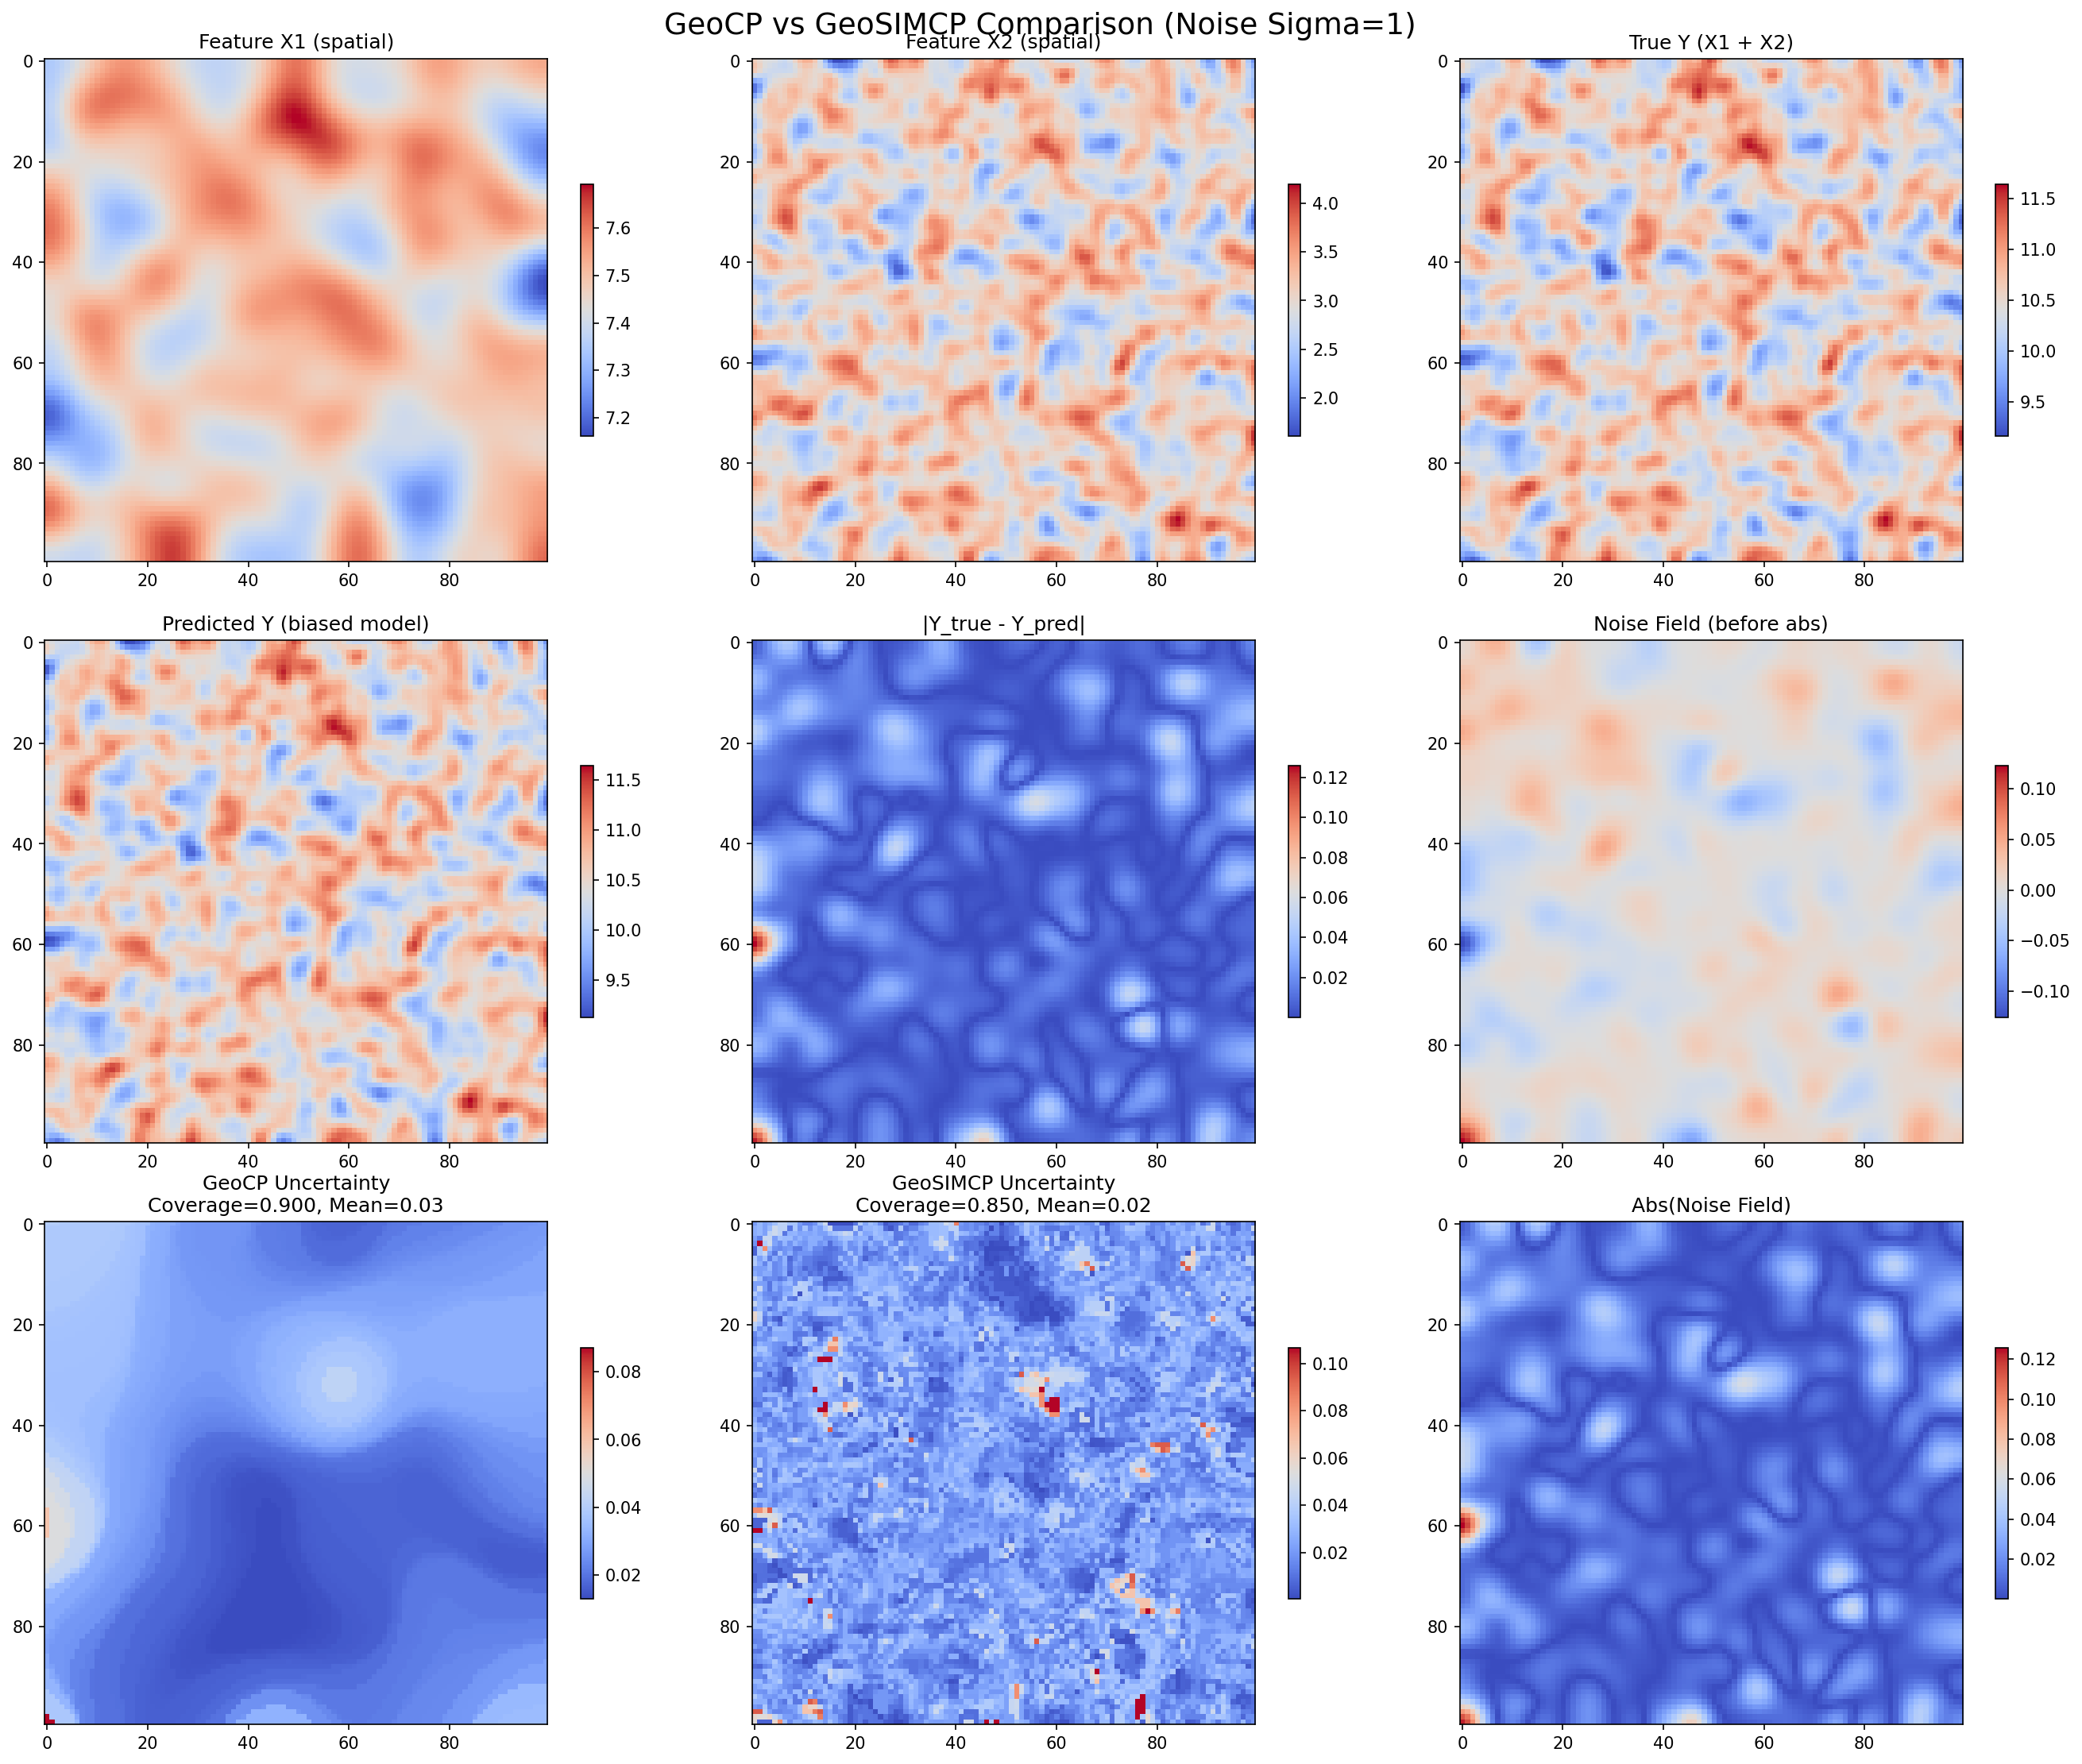

In [21]:
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
import numpy as np
import pandas as pd

# 9. 统一处理
noise_abs = np.abs(noise_grid)
geo_uncertainty_geocp_flat = geo_uncertainty_geocp.flatten()
geo_uncertainty_geosimcp_flat = geo_uncertainty_geosimcp.flatten()
noise_abs_flat = noise_abs.flatten()

# 10. 计算指标
from sklearn.metrics import mean_squared_error

def root_mean_squared_error(a, b):
    return np.sqrt(mean_squared_error(a.flatten(), b.flatten()))

def compute_corr(a, b):
    return np.corrcoef(a.flatten(), b.flatten())[0, 1]

def compute_ssim(a, b):
    return structural_similarity(a, b, data_range=np.ptp(a))

# GeoCP指标
rmse_geocp = root_mean_squared_error(noise_abs, geo_uncertainty_geocp)
corr_geocp = compute_corr(noise_abs, geo_uncertainty_geocp)
ssim_geocp = compute_ssim(noise_abs, geo_uncertainty_geocp)
coverage_geocp = results_biased_geocp.coverage_probability
mean_uncertainty_geocp = np.mean(geo_uncertainty_geocp)

# GeoSIMCP指标
rmse_geosimcp = root_mean_squared_error(noise_abs, geo_uncertainty_geosimcp)
corr_geosimcp = compute_corr(noise_abs, geo_uncertainty_geosimcp)
ssim_geosimcp = compute_ssim(noise_abs, geo_uncertainty_geosimcp)
coverage_geosimcp = results_biased_geosimcp.coverage_probability
mean_uncertainty_geosimcp = np.mean(geo_uncertainty_geosimcp)

# 11. 打印指标
print("=== GeoCP Metrics ===")
print(f"Coverage: {coverage_geocp:.4f}")
print(f"Mean Uncertainty: {mean_uncertainty_geocp:.4f}")
print(f"RMSE (vs Abs(Noise)): {rmse_geocp:.4f}")
print(f"Corr (vs Abs(Noise)): {corr_geocp:.4f}")
print(f"SSIM (vs Abs(Noise)): {ssim_geocp:.4f}")

print("\n=== GeoSIMCP Metrics ===")
print(f"Coverage: {coverage_geosimcp:.4f}")
print(f"Mean Uncertainty: {mean_uncertainty_geosimcp:.4f}")
print(f"RMSE (vs Abs(Noise)): {rmse_geosimcp:.4f}")
print(f"Corr (vs Abs(Noise)): {corr_geosimcp:.4f}")
print(f"SSIM (vs Abs(Noise)): {ssim_geosimcp:.4f}")

# 12. 可视化 (3行3列)
fig, axes = plt.subplots(3, 3, figsize=(18, 15), dpi=150)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9 = axes.ravel()

# X1
c1 = ax1.imshow(X1.reshape(100, 100), cmap='coolwarm')
fig.colorbar(c1, ax=ax1, shrink=0.5)
ax1.set_title("Feature X1 (spatial)")

# X2
c2 = ax2.imshow(X2.reshape(100, 100), cmap='coolwarm')
fig.colorbar(c2, ax=ax2, shrink=0.5)
ax2.set_title("Feature X2 (spatial)")

# True Y
c3 = ax3.imshow(true_y_grid, cmap='coolwarm')
fig.colorbar(c3, ax=ax3, shrink=0.5)
ax3.set_title("True Y (X1 + X2)")

# Predicted Y
c4 = ax4.imshow(y_pred_geocp, cmap='coolwarm')
fig.colorbar(c4, ax=ax4, shrink=0.5)
ax4.set_title("Predicted Y (biased model)")

# Prediction Error
c5 = ax5.imshow(y_error, cmap='coolwarm')
fig.colorbar(c5, ax=ax5, shrink=0.5)
ax5.set_title("|Y_true - Y_pred|")

# Noise Field
c6 = ax6.imshow(noise_grid, cmap='coolwarm')
fig.colorbar(c6, ax=ax6, shrink=0.5)
ax6.set_title("Noise Field (before abs)")

# GeoCP Uncertainty
c7 = ax7.imshow(geo_uncertainty_geocp, cmap='coolwarm')
fig.colorbar(c7, ax=ax7, shrink=0.5)
ax7.set_title(f"GeoCP Uncertainty\nCoverage={coverage_geocp:.3f}, Mean={mean_uncertainty_geocp:.2f}")

# GeoSIMCP Uncertainty
c8 = ax8.imshow(geo_uncertainty_geosimcp, cmap='coolwarm')
fig.colorbar(c8, ax=ax8, shrink=0.5)
ax8.set_title(f"GeoSIMCP Uncertainty\nCoverage={coverage_geosimcp:.3f}, Mean={mean_uncertainty_geosimcp:.2f}")

# Abs(Noise Field)
c9 = ax9.imshow(noise_abs, cmap='coolwarm')
fig.colorbar(c9, ax=ax9, shrink=0.5)
ax9.set_title("Abs(Noise Field)")

fig.suptitle(f"GeoCP vs GeoSIMCP Comparison (Noise Sigma={noise_sigma})", fontsize=18)
plt.tight_layout()
plt.show()

# ✅ 如果要保存高质量版
# plt.savefig('comparison_geocp_geosimcp_fullgrid.pdf', dpi=300)

# 测试GeoSIMCP和GeoCP的参数最优化

In [22]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# ===================================
# ✨ 1. interval_score
# ===================================
def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    """
    Interval score for prediction intervals
    """
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    return width + (2 / alpha) * (below + above)

# ===================================
# ✨ 2. GeoCP的bandwidth sweep
# ===================================
def bandwidth_grid_sweep_geocp(
    bandwidth_list,
    predict_f,
    X_val,
    X_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    noise_abs=None,
    alpha=0.1,
    coverage_threshold=0.9
):
    from GeoConformalSpatialRegression import GeoConformalSpatialRegression  # 确保有这个类

    coverage_list = []
    uncertainty_list = []
    interval_score_list = []
    rmse_list = []
    r2_list = []

    for bw in bandwidth_list:
        model = GeoConformalSpatialRegression(
            predict_f=predict_f,
            miscoverage_level=alpha,
            bandwidth=bw,
            coord_calib=loc_val.values,
            coord_test=loc_test.values,
            X_calib=X_val,
            y_calib=y_val,
            X_test=X_test,
            y_test=y_test
        )

        result = model.analyze()
        coverage_list.append(result.coverage_probability)

        unc = np.array(result.geo_uncertainty)
        unc = unc[~np.isnan(unc)]
        uncertainty_list.append(np.mean(unc) if len(unc) > 0 else np.nan)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        interval_score_list.append(np.mean(score))

        if noise_abs is not None:
            geo_uncertainty = result.geo_uncertainty.reshape(noise_abs.shape)
            rmse = np.sqrt(mean_squared_error(noise_abs.flatten(), geo_uncertainty.flatten()))
            rmse_list.append(rmse)
            r2 = r2_score(noise_abs.flatten(), geo_uncertainty.flatten())
            r2_list.append(r2)
        else:
            rmse_list.append(np.nan)
            r2_list.append(np.nan)

    mask = np.array(coverage_list) >= coverage_threshold
    masked_score = np.where(mask, interval_score_list, np.inf)
    best_idx = np.argmin(masked_score)
    best_bw = bandwidth_list[best_idx]

    print(f"✅ GeoCP Optimal Parameters Summary:")
    print(f"  Best Bandwidth   = {best_bw:.3f}")
    print(f"  Coverage         = {coverage_list[best_idx]:.3f}")
    print(f"  Interval Score   = {interval_score_list[best_idx]:.3f}")
    print(f"  Mean Uncertainty = {uncertainty_list[best_idx]:.3f}")
    print(f"  RMSE             = {rmse_list[best_idx]:.3f}")
    print(f"  R²               = {r2_list[best_idx]:.3f}")

    return {
        'coverage': coverage_list[best_idx],
        'interval_score': interval_score_list[best_idx],
        'mean_uncertainty': uncertainty_list[best_idx],
        'rmse': rmse_list[best_idx],
        'r2': r2_list[best_idx],
        'nrmse': rmse_list[best_idx] / (noise_abs.max() - noise_abs.min()) if noise_abs is not None else np.nan,
        'best_bandwidth': best_bw
    }

# ===================================
# ✨ 3. GeoSIMCP的bandwidth × lambda sweep
# ===================================
def select_best_lambda_bandwidth(coverage_grid, score_grid, lambda_list, bandwidth_list, threshold=0.9):
    mask = coverage_grid >= threshold
    masked_score = np.where(mask, score_grid, np.inf)
    idx = np.unravel_index(np.argmin(masked_score), masked_score.shape)
    best_lambda = lambda_list[idx[1]]
    best_bandwidth = bandwidth_list[idx[0]]
    return best_lambda, best_bandwidth, masked_score[idx], idx

def geosimcp_bandwidth_lambda_grid_sweep(
    bandwidth_list,
    lambda_list,
    predict_f,
    X_spatial_val,
    X_spatial_test,
    X_aspatial_val,
    X_aspatial_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    noise_abs=None,
    alpha=0.1,
    coverage_threshold=0.9
):
    from GeoSIMCP import GeoSIMConformalSpatialRegression  # 确保有这个类

    coverage_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    uncertainty_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    interval_score_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    rmse_grid = np.full_like(interval_score_grid, np.nan)
    r2_grid = np.full_like(interval_score_grid, np.nan)

    for i, bw in enumerate(bandwidth_list):
        for j, lam in enumerate(lambda_list):
            try:
                model = GeoSIMConformalSpatialRegression(
                    predict_f=predict_f,
                    miscoverage_level=alpha,
                    bandwidth=bw,
                    coord_calib=loc_val.values,
                    coord_test=loc_test.values,
                    X_calib=X_spatial_val,
                    X_test=X_spatial_test,
                    y_calib=y_val,
                    y_test=y_test,
                    X_calib_weight=X_aspatial_val,
                    X_test_weight=X_aspatial_test,
                    lambda_weight=lam
                )
                result = model.analyze()

                coverage_grid[i, j] = result.coverage_probability
                uncertainty_grid[i, j] = np.mean(result.geo_uncertainty)

                lower = np.array(result.lower_bound)
                upper = np.array(result.upper_bound)
                y_true = np.array(y_test)

                score = interval_score(y_true, lower, upper, alpha=alpha)
                interval_score_grid[i, j] = np.mean(score)

                if noise_abs is not None:
                    geo_uncertainty = result.geo_uncertainty.reshape(noise_abs.shape)
                    rmse_grid[i, j] = np.sqrt(mean_squared_error(noise_abs.flatten(), geo_uncertainty.flatten()))
                    r2_grid[i, j] = r2_score(noise_abs.flatten(), geo_uncertainty.flatten())

            except Exception as e:
                print(f"❌ Model failed at bandwidth={bw:.3f}, lambda={lam:.3f}")
                print(f"   Error: {str(e)}")
                continue

    best_lambda, best_bw, best_score, idx = select_best_lambda_bandwidth(
        coverage_grid, interval_score_grid, lambda_list, bandwidth_list, threshold=coverage_threshold
    )
    best_coverage = coverage_grid[idx]
    best_uncertainty = uncertainty_grid[idx]

    print("\n✅ GeoSIMCP Optimal Parameters Summary:")
    print(f"  Best Bandwidth  = {best_bw:.3f}")
    print(f"  Best Lambda     = {best_lambda:.3f}")
    print(f"  Coverage        = {best_coverage:.3f}")
    print(f"  Interval Score  = {best_score:.3f}")
    print(f"  Mean Uncertainty= {best_uncertainty:.3f}")
    if noise_abs is not None:
        print(f"  RMSE            = {rmse_grid[idx]:.3f}")
        print(f"  R2              = {r2_grid[idx]:.3f}")

    return {
        'coverage': best_coverage,
        'interval_score': best_score,
        'mean_uncertainty': best_uncertainty,
        'rmse': rmse_grid[idx],
        'r2': r2_grid[idx],
        'nrmse': rmse_grid[idx] / (noise_abs.max() - noise_abs.min()) if noise_abs is not None else np.nan,
        'best_bandwidth': best_bw,
        'best_lambda': best_lambda
    }

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

def batch_run_geocp_geosimcp(
    noise_sigma_list=None,
    noise_std_list=None,
    grid_size=100,
    base_X_coords=None,
    X1=None,
    X2=None,
    true_y=None,
    df_coord_to_feat=None,
    create_coord_noise_df=None,
    biased_model_predict=None,
    bandwidth_list_geocp=None,
    bandwidth_list_geosimcp=None,
    lambda_list_geosimcp=None,
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="geo_cp_vs_simcp_batch",
    feature_space_noise=False    # ✅ 新增！决定是否用特征空间生成噪声
):
    results = []

    if noise_sigma_list is None:
        noise_sigma_list = [3.0]
    if noise_std_list is None:
        noise_std_list = [1.0]

    for noise_sigma in tqdm(noise_sigma_list, desc="Sigma Loop"):
        for noise_std in tqdm(noise_std_list, desc="STD Loop", leave=False):

            if feature_space_noise:
                # ✅ 特征空间聚集噪声
                X_features = np.vstack([X1, X2]).T
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,                  # 这个在feature_space里其实不怎么起作用，但统一传进去
                    feature_space_cluster=True,          # ✅ 开启
                    X_features=X_features,
                    cluster_center=(7, 2),               # 可以参数化
                    cluster_width=0.5,                   # 可以参数化
                    seed=42
                )
            else:
                # ✅ 地理空间高斯噪声
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    seed=42
                )

            # 构建predict函数
            predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)

            # 基础变量准备
            X_features = np.vstack([X1, X2]).T
            noise_abs = np.abs(df_coord_to_noise["noise"].values.reshape(grid_size, grid_size))

            # GeoCP tuning
            geocp_metrics = bandwidth_grid_sweep_geocp(
                bandwidth_list=bandwidth_list_geocp,
                predict_f=predict_f,
                X_val=loc_val,
                X_test=base_X_coords,
                y_val=y_val,
                y_test=true_y,
                loc_val=loc_val,
                loc_test=base_X_coords,
                noise_abs=noise_abs,
                alpha=alpha,
                coverage_threshold=coverage_threshold
            )

            # GeoSIMCP tuning
            geosimcp_metrics = geosimcp_bandwidth_lambda_grid_sweep(
                bandwidth_list=bandwidth_list_geosimcp,
                lambda_list=lambda_list_geosimcp,
                predict_f=predict_f,
                X_spatial_val=loc_val,
                X_spatial_test=base_X_coords,
                X_aspatial_val=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
                X_aspatial_test=pd.DataFrame(X_features, columns=["X1", "X2"]),
                y_val=y_val,
                y_test=true_y,
                loc_val=loc_val,
                loc_test=base_X_coords,
                noise_abs=noise_abs,
                alpha=alpha,
                coverage_threshold=coverage_threshold
            )

            # 保存每次结果
            results.append({
                'noise_sigma': noise_sigma,
                'noise_std': noise_std,
                'method': 'GeoCP',
                **geocp_metrics
            })
            results.append({
                'noise_sigma': noise_sigma,
                'noise_std': noise_std,
                'method': 'GeoSIMCP',
                **geosimcp_metrics
            })

    # 汇总所有结果
    results_df = pd.DataFrame(results)

    results_df.to_csv(f"{save_prefix}_metrics.csv", index=False)
    print(f"✅ All results saved to {save_prefix}_metrics.csv")

    return results_df


def plot_batch_results(
    results_df,
    save_prefix="geo_cp_vs_simcp_batch",
    x_axis="noise_std",           # ✅ 新增参数，默认横轴是noise_std
    fixed_value=None,             # ✅ 可选，固定另一个参数，比如固定noise_sigma=3
    fixed_param="noise_sigma"     # ✅ 默认固定noise_sigma
):
    """
    绘制 batch 实验结果
    - x_axis: 选择横轴是 'noise_std' 或 'noise_sigma'
    - fixed_value: 如果指定，表示只绘制固定另一个参数取特定值的子集
    - fixed_param: 指定固定哪个参数，'noise_sigma' 或 'noise_std'
    """

    indicators = ['coverage', 'interval_score', 'mean_uncertainty', 'rmse', 'r2']

    for indicator in indicators:
        plt.figure(figsize=(6, 4), dpi=150)

        for method in results_df['method'].unique():
            subset = results_df[results_df['method'] == method]

            # 如果指定了固定值，只画满足条件的子集
            if fixed_value is not None:
                subset = subset[subset[fixed_param] == fixed_value]

            subset = subset.sort_values(by=x_axis)

            plt.plot(subset[x_axis], subset[indicator], label=method, marker='o')

        plt.title(f"{indicator} vs {x_axis.replace('_', ' ').title()}")
        plt.xlabel(x_axis.replace('_', ' ').title())
        plt.ylabel(indicator)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        # 文件名也反映x轴和固定的参数
        save_name = f"{save_prefix}_{indicator}_x-{x_axis}"
        if fixed_value is not None:
            save_name += f"_fixed-{fixed_param}-{fixed_value}"

        plt.savefig(f"{save_name}.pdf")
        plt.show()


STD Loop:   0%|          | 0/1 [00:00<?, ?it/s]

✅ GeoCP Optimal Parameters Summary:
  Best Bandwidth   = 1.389
  Coverage         = 0.900
  Interval Score   = 0.010
  Mean Uncertainty = 0.003
  RMSE             = 0.002
  R²               = -0.999



Sigma Loop: 100%|██████████| 1/1 [02:05<00:00, 125.94s/it]


✅ GeoSIMCP Optimal Parameters Summary:
  Best Bandwidth  = 0.422
  Best Lambda     = 0.000
  Coverage        = 0.939
  Interval Score  = 0.006
  Mean Uncertainty= 0.002
  RMSE            = 0.002
  R2              = -0.175
✅ All results saved to geo_cp_vs_simcp_batch_metrics.csv


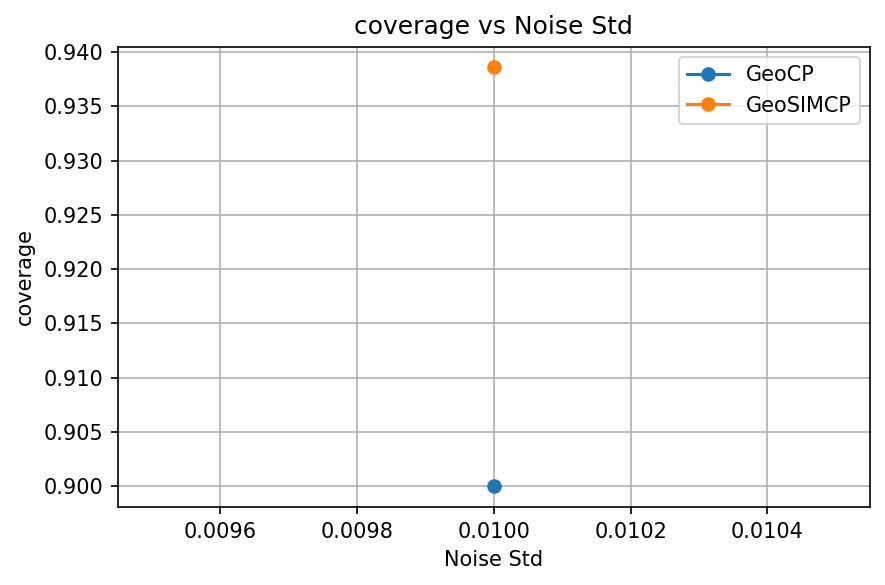

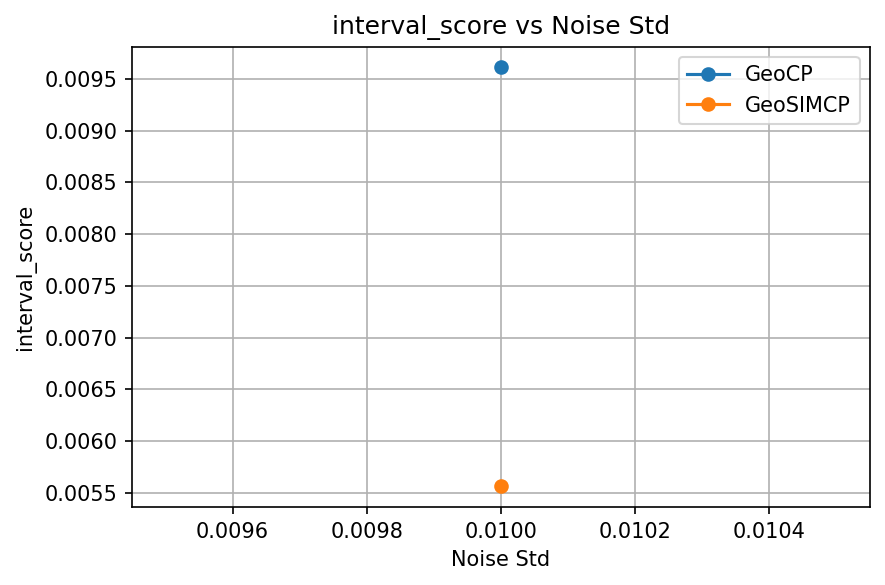

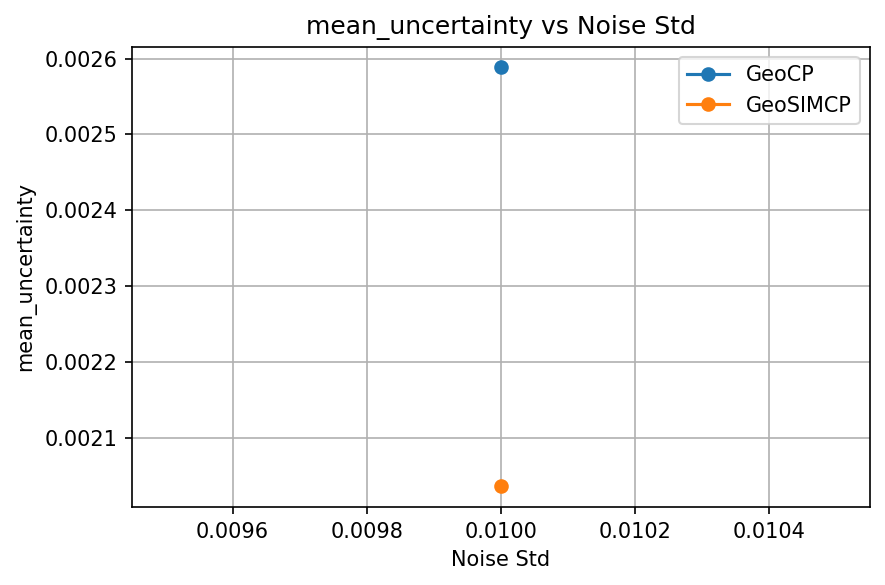

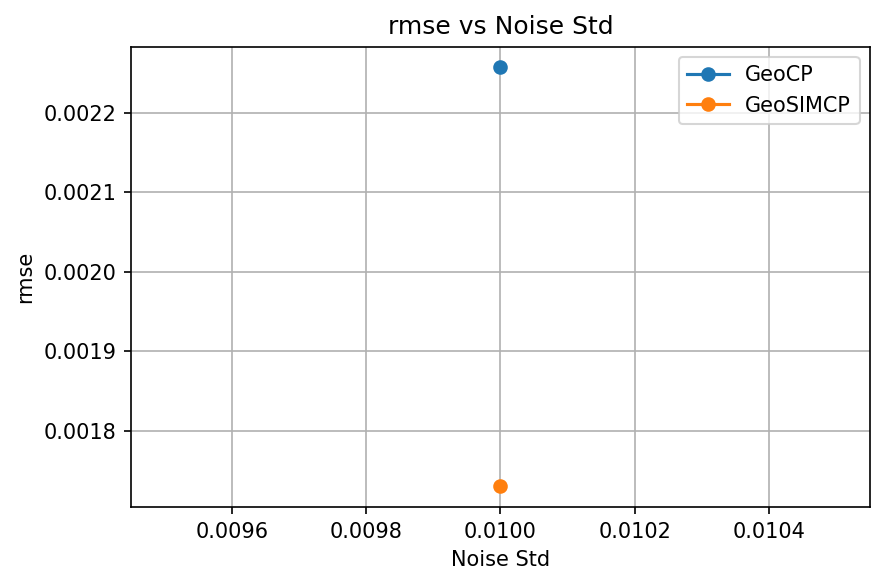

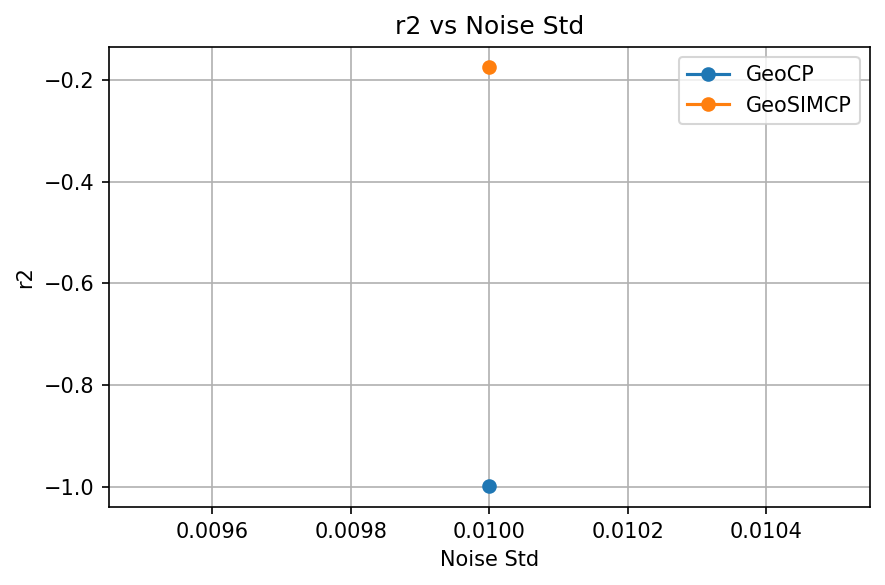

In [24]:
results_df = batch_run_geocp_geosimcp(
 #   noise_std_list=[2.0],
  #  noise_std_list=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9, 1.0, 1.5, 2.0, 3, 4, 5.0, 6, 7, 8, 9, 15, 20],
   # noise_std_list=[0,0.01,0.02,0.03,0.04,0.05,0.07,0.08,0.09,0.1,0.5,1,2,3,4,5,10,15,20],


 # noise_sigma_list=[0.1,0.5,1,1.5,2,2.5,3,5,10],
    #noise_std_list=[0,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.5,1,2,3,4,5,10],

    noise_sigma_list=[0.1],
    noise_std_list=[0.01],


    grid_size=100,
    base_X_coords=X_coords,
    X1=X1,
    X2=X2,
    true_y=true_y,
    df_coord_to_feat=df_coord_to_feat,
    create_coord_noise_df=create_coord_noise_df,
    biased_model_predict=biased_model_predict,
    bandwidth_list_geocp=np.linspace(0.1, 3, 10),
    bandwidth_list_geosimcp=np.linspace(0.1, 3, 10),
    lambda_list_geosimcp=np.linspace(0, 1, 6),
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="geo_cp_vs_simcp_batch",
    feature_space_noise=True         # ✅ 开启特征空间噪声！
)
results_df.to_csv("/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study/geo_cp_vs_simcp_feature_noise_0501.csv", index=False)
plot_batch_results(results_df, save_prefix="geo_cp_vs_simcp_batch", x_axis="noise_std")


In [ ]:
results_df

,noise_sigma,noise_std,method,coverage,interval_score,mean_uncertainty,rmse,r2,nrmse,best_bandwidth,best_lambda
0,0.1,0.01,GeoCP,0.9000,0.009611,0.002588,0.002257,-0.999097,0.102773,1.388889,NaN
1,0.1,0.01,GeoSIMCP,0.9386,0.005564,0.002036,0.001730,-0.175257,0.078800,0.422222,0.0


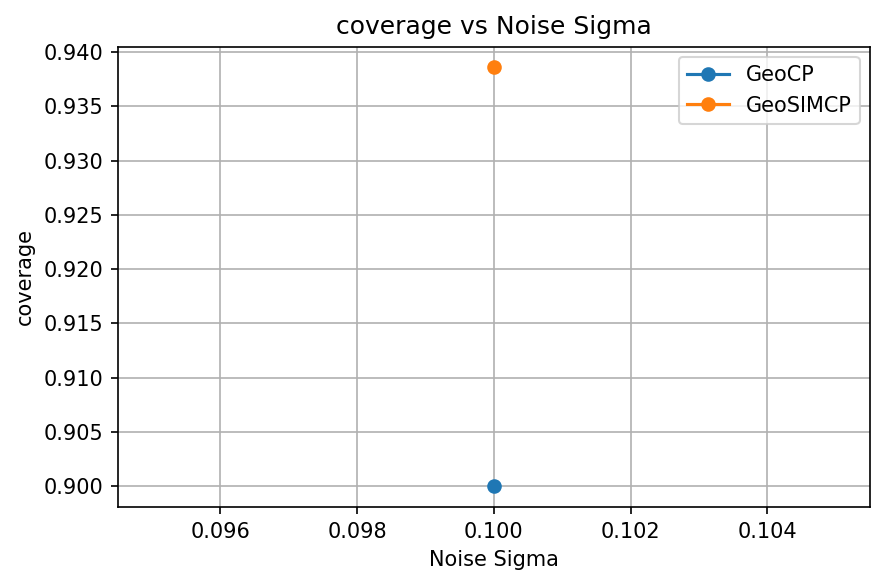

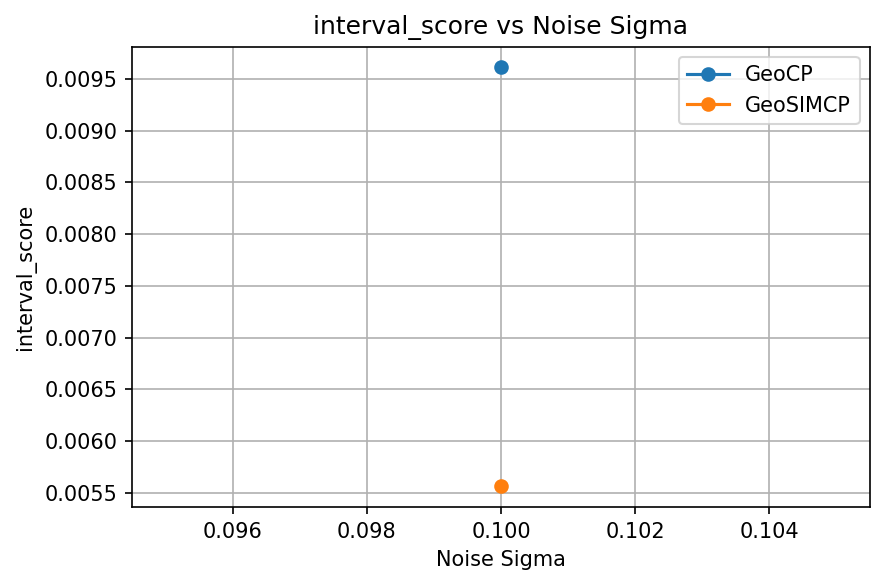

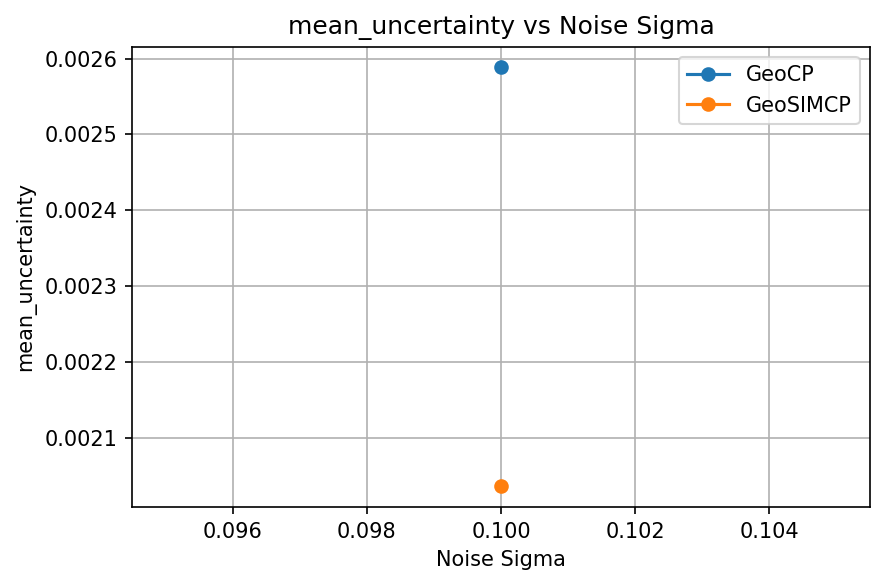

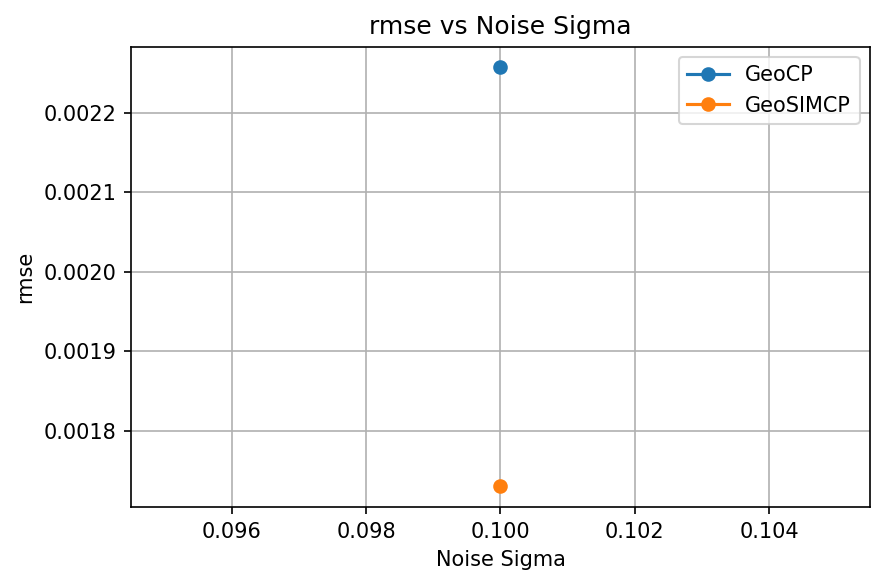

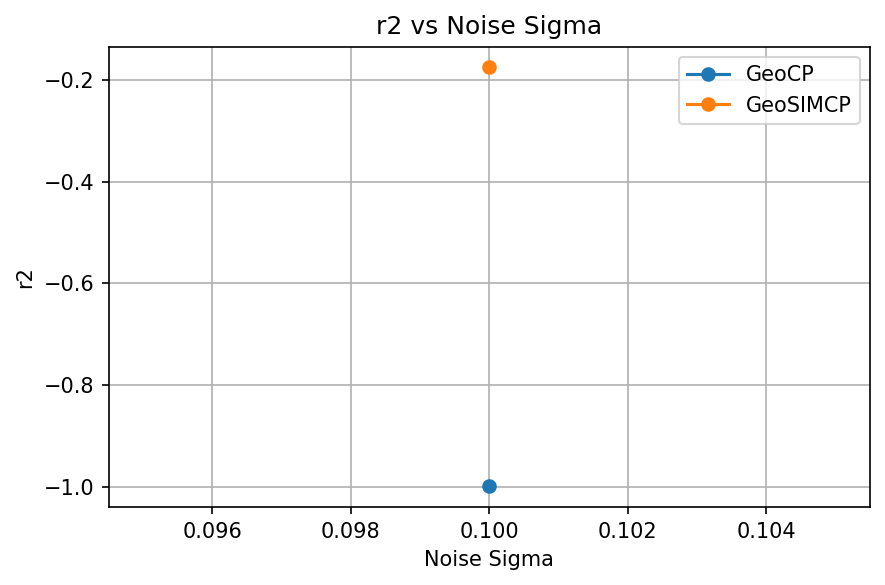

In [ ]:
plot_batch_results(results_df, save_prefix="geo_cp_vs_simcp_batch", x_axis="noise_sigma")


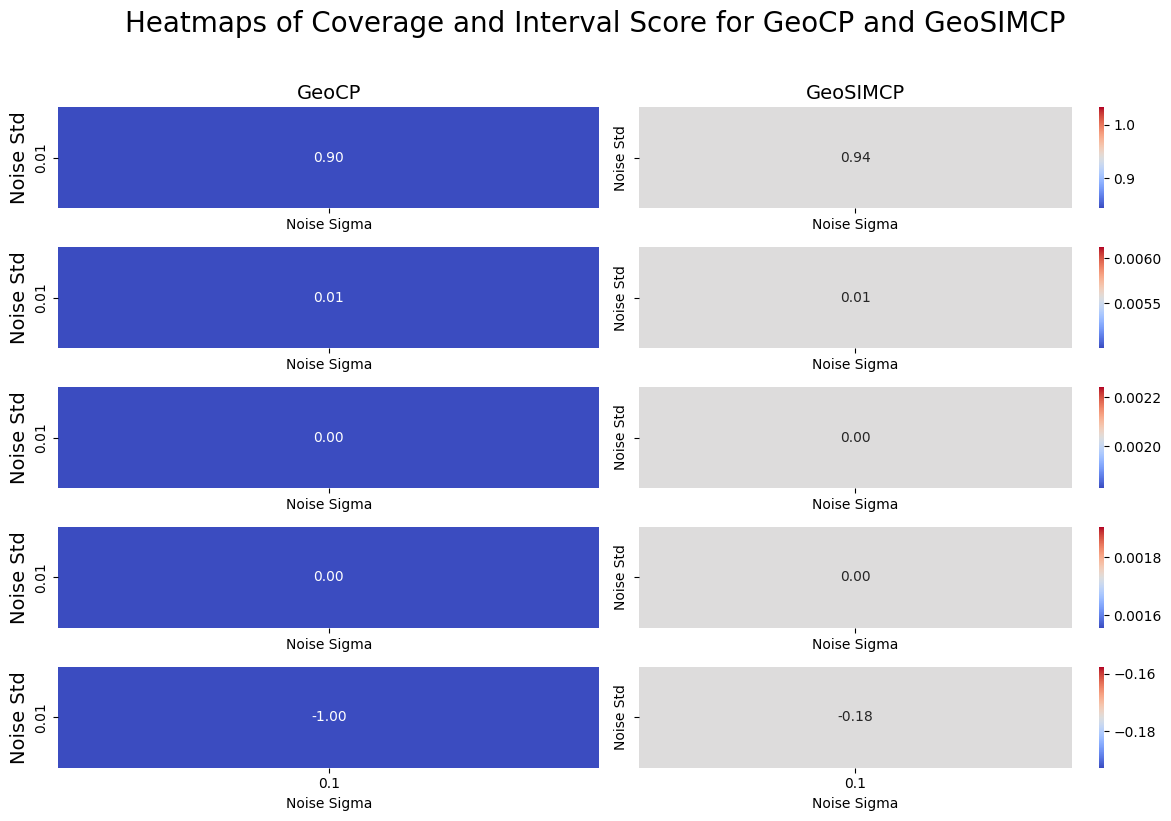

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["coverage", "interval_score", "mean_uncertainty", "rmse", "r2"]
methods = results_df['method'].unique()

fig, axes = plt.subplots(len(metrics), len(methods), figsize=(12, 8), sharex=True, sharey=True)

for row_idx, metric in enumerate(metrics):
    for col_idx, method in enumerate(methods):
        df_sub = results_df[results_df['method'] == method]
        pivot_table = df_sub.pivot_table(index="noise_std", columns="noise_sigma", values=metric)

        sns.heatmap(
            pivot_table,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[row_idx, col_idx],
            cbar=(col_idx == len(methods) - 1)
        )
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(f"{method}", fontsize=14)
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(f"{metric}", fontsize=14)

for ax in axes.flatten():
    ax.set_xlabel("Noise Sigma")
    ax.set_ylabel("Noise Std")

fig.suptitle("Heatmaps of Coverage and Interval Score for GeoCP and GeoSIMCP", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()


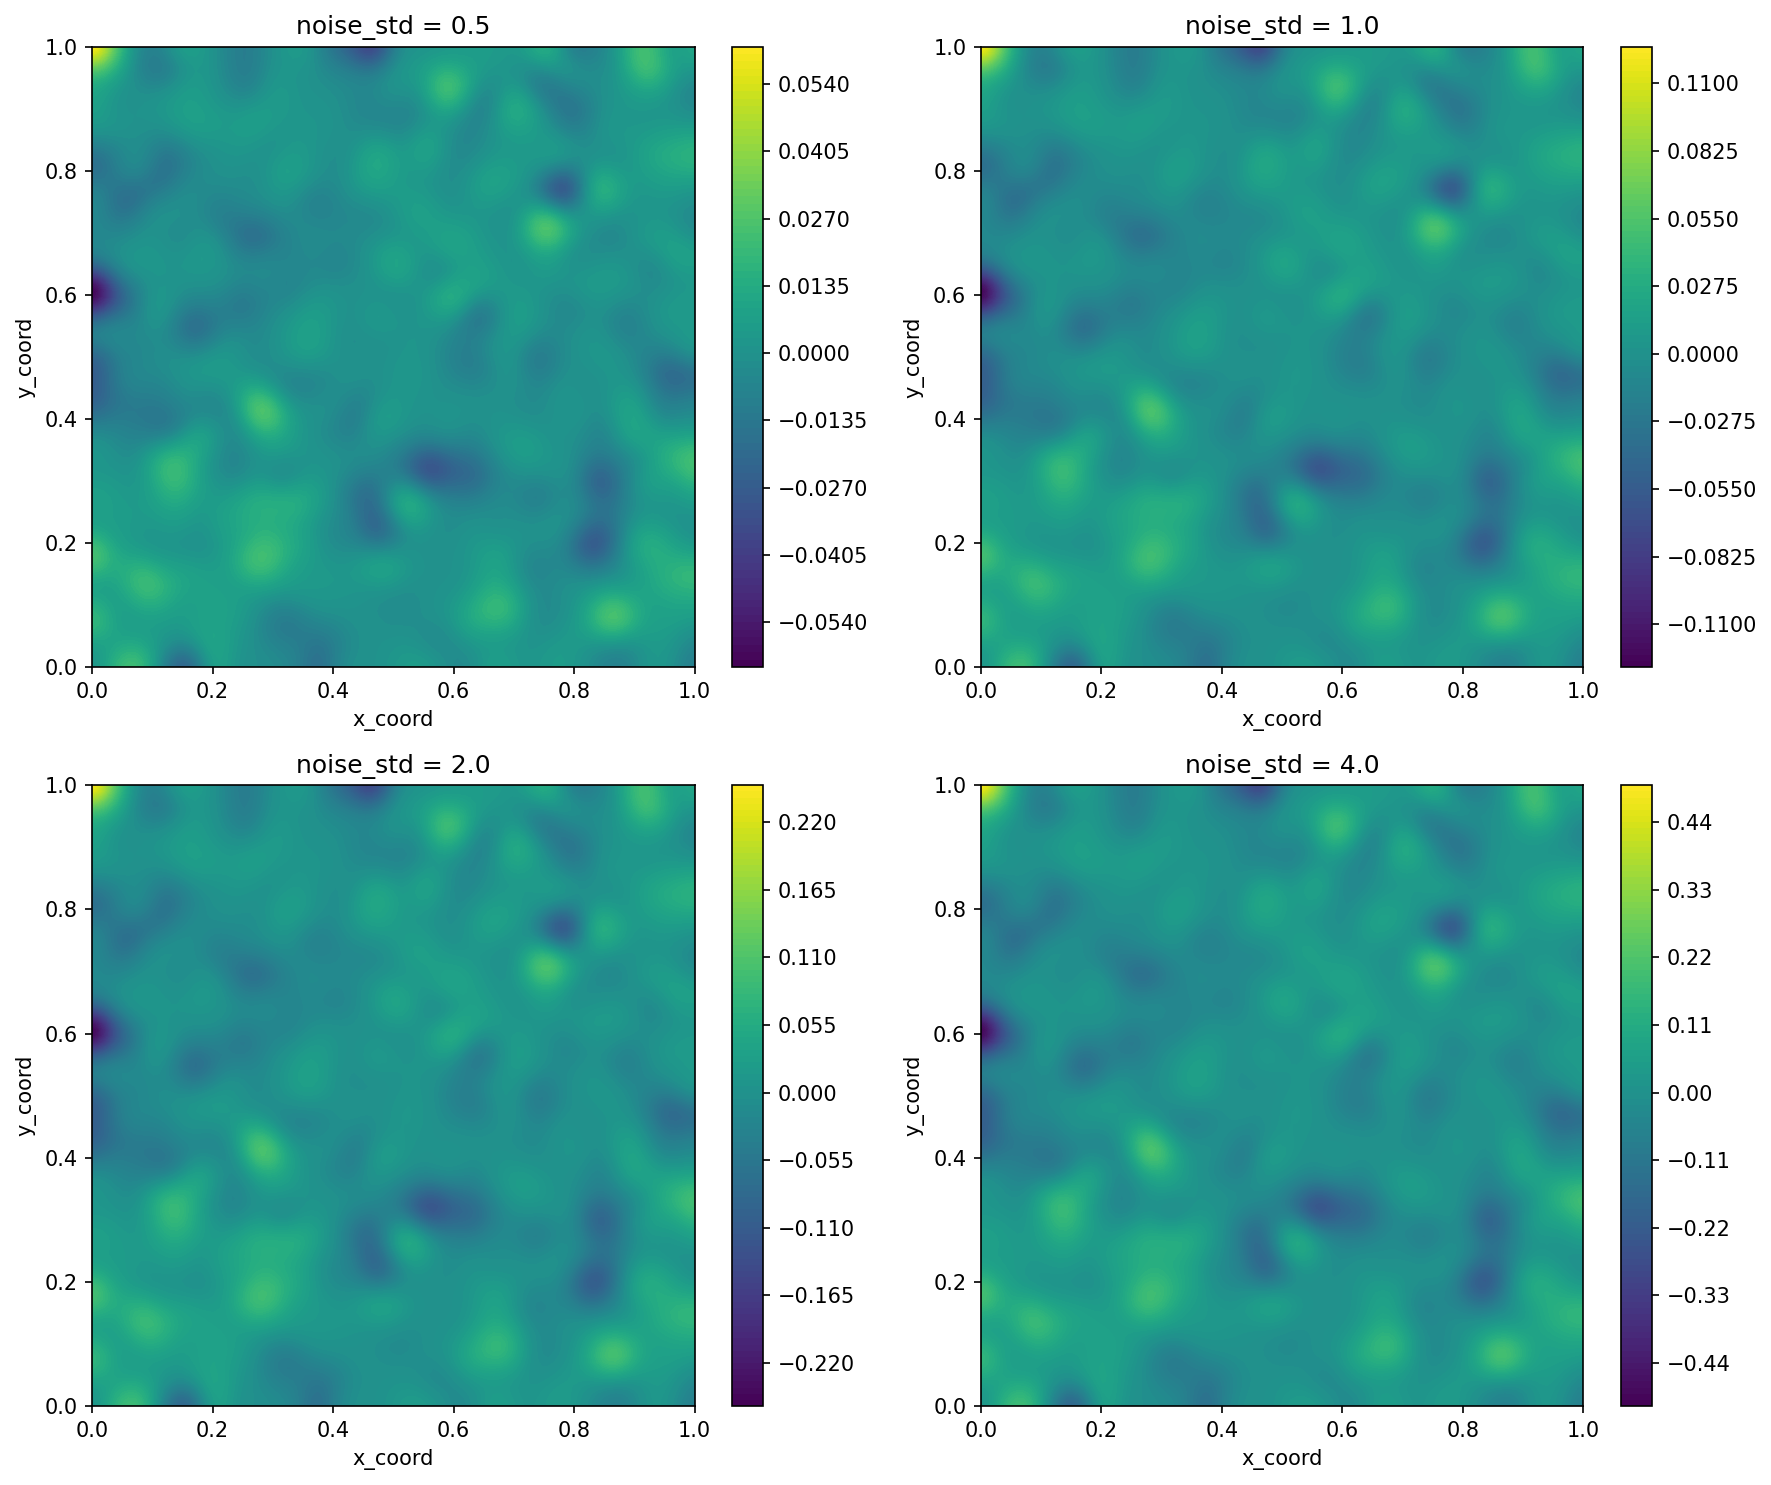

In [ ]:
def plot_noise_std_series(
    noise_std_list,
    create_coord_noise_df,
    X_coords,
    X_features,
    grid_size=100,
    feature_space_cluster=True,
    cluster_center=(7, 2),
    cluster_width=0.5,
    sigma=3,
    seed=42
):
    """
    对一组 noise_std 进行循环绘图，展示噪声在地理空间的分布。
    """
    import matplotlib.pyplot as plt
    import numpy as np

    n = len(noise_std_list)
    ncols = 2
    nrows = (n + 1) // 2

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows), dpi=150)

    for i, noise_std in enumerate(noise_std_list):
        ax = axes.flat[i]

        df_noise = create_coord_noise_df(
            X_coords=X_coords,
            grid_size=grid_size,
            noise_std=noise_std,
            sigma=sigma,
            seed=seed,
            feature_space_cluster=feature_space_cluster,
            X_features=X_features,
            cluster_center=cluster_center,
            cluster_width=cluster_width
        )

        x = df_noise["x_coord"].values.reshape(grid_size, grid_size)
        y = df_noise["y_coord"].values.reshape(grid_size, grid_size)
        z = df_noise["noise"].values.reshape(grid_size, grid_size)

        contour = ax.contourf(x, y, z, levels=100, cmap="viridis")
        ax.set_title(f"noise_std = {noise_std}")
        ax.set_xlabel("x_coord")
        ax.set_ylabel("y_coord")
        fig.colorbar(contour, ax=ax)

    # 去掉空子图（如果有）
    for j in range(i + 1, nrows * ncols):
        fig.delaxes(axes.flat[j])

    plt.tight_layout()
    plt.show()
noise_std_list = [0.5, 1.0, 2.0, 4.0]

plot_noise_std_series(
    noise_std_list=noise_std_list,
    create_coord_noise_df=create_coord_noise_df,
    X_coords=X_coords,
    X_features=np.vstack([X1, X2]).T,
    grid_size=100
)


# GeoCP and GeoSIMCP空间可视化

In [ ]:
# noise_sigmas = [0.1, 0.5, 1, 1.5, 2, 2.5, 3, 5, 10]

# for noise_sigma in noise_sigmas:

#     print(f"\n========== Noise sigma = {noise_sigma} ==========")

#     # ===============================
#     # 1. 构建 100×100 网格
#     # ===============================
#     grid_size = 100
#     x = np.linspace(0, 1, grid_size)
#     y = np.linspace(0, 1, grid_size)
#     X_grid, Y_grid = np.meshgrid(x, y)
#     coords = np.stack([X_grid.ravel(), Y_grid.ravel()], axis=1)
#     X_coords = pd.DataFrame(coords, columns=["x_coord", "y_coord"])

#     # ===============================
#     # 2. 构建空间特征 X1, X2（固定）
#     # ===============================
#     np.random.seed(42)
#     X1 = gaussian_filter(
#         np.random.uniform(5, 10, size=(grid_size, grid_size)), sigma=5
#     ).ravel()
#     X2 = gaussian_filter(
#         np.random.uniform(0, 6, size=(grid_size, grid_size)), sigma=1.5
#     ).ravel()

#     true_y = X1 + X2

#     df_coord_to_feat = X_coords.copy()
#     df_coord_to_feat["X1"] = X1
#     df_coord_to_feat["X2"] = X2

#     # ===============================
#     # 3. ✅ 生成「真正随 sigma 变化」的噪声
#     # ===============================
#     # 👉 使用 feature-space clustered noise
#     df_coord_to_noise = create_coord_noise_df(
#         X_coords=X_coords,
#         grid_size=grid_size,
#         noise_std=1,
#         feature_space_cluster=True,
#         X_features=np.vstack([X1, X2]).T,
#         cluster_center=(7, 2),
#         cluster_width=0.3 * noise_sigma,   # ✅ sigma 生效！
#         seed=None                            # ✅ 不固定
#     )

#     # ===============================
#     # 4. biased predictor
#     # ===============================
#     predict_f = lambda X_df: biased_model_predict(
#         X_df, df_coord_to_feat, df_coord_to_noise
#     )

#     # ===============================
#     # 5. 拆分 calibration / test
#     # ===============================
#     (
#         X_spatial_train, X_spatial_temp,
#         X_aspatial_train, X_aspatial_temp,
#         y_train, y_temp,
#         loc_train, loc_temp
#     ) = train_test_split(
#         X_coords,
#         np.vstack([X1, X2]).T,
#         true_y,
#         X_coords,
#         train_size=0.8,
#         random_state=42
#     )

#     (
#         X_spatial_val, X_spatial_test,
#         X_aspatial_val, X_aspatial_test,
#         y_val, y_test,
#         loc_val, loc_test
#     ) = train_test_split(
#         X_spatial_temp,
#         X_aspatial_temp,
#         y_temp,
#         loc_temp,
#         train_size=0.5,
#         random_state=42
#     )

#     # ===============================
#     # 6. GeoCP（10000 测试点）
#     # ===============================
#     geocp = GeoConformalSpatialRegression(
#         predict_f=predict_f,
#         miscoverage_level=0.1,
#         bandwidth=0.1,
#         coord_calib=loc_val.values,
#         coord_test=X_coords.values,
#         X_calib=loc_val.copy(),
#         y_calib=y_val,
#         X_test=X_coords.copy(),
#         y_test=true_y
#     )

#     res_geocp = geocp.analyze().to_gpd()

#     geo_uncertainty_geocp = res_geocp["geo_uncertainty"].values.reshape(grid_size, grid_size)
#     y_pred_geocp = predict_f(X_coords).reshape(grid_size, grid_size)

#     # ===============================
#     # 7. GeoSIMCP（10000 测试点）
#     # ===============================
#     geosimcp = GeoSIMConformalSpatialRegression(
#         predict_f=predict_f,
#         miscoverage_level=0.1,
#         bandwidth=0.1,
#         lambda_weight=0.0,
#         coord_calib=loc_val.values,
#         coord_test=X_coords.values,
#         X_calib=loc_val.copy(),
#         X_test=X_coords.copy(),
#         X_calib_weight=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
#         X_test_weight=pd.DataFrame(np.vstack([X1, X2]).T, columns=["X1", "X2"]),
#         y_calib=y_val,
#         y_test=true_y
#     )

#     res_geosimcp = geosimcp.analyze().to_gpd()
#     geo_uncertainty_geosimcp = res_geosimcp["geo_uncertainty"].values.reshape(grid_size, grid_size)

#     # ===============================
#     # 8. 指标计算
#     # ===============================
#     noise_abs = np.abs(df_coord_to_noise["noise"].values.reshape(grid_size, grid_size))

#     def rmse(a, b):
#         return np.sqrt(mean_squared_error(a.ravel(), b.ravel()))

#     def corr(a, b):
#         return np.corrcoef(a.ravel(), b.ravel())[0, 1]

#     def ssim(a, b):
#         return structural_similarity(a, b, data_range=np.ptp(a))

#     print("GeoCP   | RMSE:", rmse(noise_abs, geo_uncertainty_geocp),
#           "Corr:", corr(noise_abs, geo_uncertainty_geocp),
#           "SSIM:", ssim(noise_abs, geo_uncertainty_geocp))

#     print("GeoSIMCP| RMSE:", rmse(noise_abs, geo_uncertainty_geosimcp),
#           "Corr:", corr(noise_abs, geo_uncertainty_geosimcp),
#           "SSIM:", ssim(noise_abs, geo_uncertainty_geosimcp))

#     # ===============================
#     # 9. 可视化（3×3）
#     # ===============================
#    # ===============================
# # 9. 可视化（3×3，每个图都有 colorbar）
# # ===============================
#     fig, axes = plt.subplots(3, 3, figsize=(18, 15), dpi=150)
#     ax = axes.ravel()

#     # X1
#     im0 = ax[0].imshow(X1.reshape(grid_size, grid_size), cmap="coolwarm")
#     ax[0].set_title("Feature X1")
#     fig.colorbar(im0, ax=ax[0], shrink=0.8, pad=0.01)

#     # X2
#     im1 = ax[1].imshow(X2.reshape(grid_size, grid_size), cmap="coolwarm")
#     ax[1].set_title("Feature X2")
#     fig.colorbar(im1, ax=ax[1], shrink=0.8, pad=0.01)

#     # True Y
#     im2 = ax[2].imshow(true_y.reshape(grid_size, grid_size), cmap="coolwarm")
#     ax[2].set_title("True Y (X1 + X2)")
#     fig.colorbar(im2, ax=ax[2], shrink=0.8, pad=0.01)

#     # Predicted Y
#     im3 = ax[3].imshow(y_pred_geocp, cmap="coolwarm")
#     ax[3].set_title("Predicted Y (biased model)")
#     fig.colorbar(im3, ax=ax[3], shrink=0.8, pad=0.01)

#     # Prediction Error
#     im4 = ax[4].imshow(
#         np.abs(true_y.reshape(grid_size, grid_size) - y_pred_geocp),
#         cmap="coolwarm"
#     )
#     ax[4].set_title("|Y_true - Y_pred|")
#     fig.colorbar(im4, ax=ax[4], shrink=0.8, pad=0.01)

#     # Abs Noise
#     im5 = ax[5].imshow(noise_abs, cmap="coolwarm")
#     ax[5].set_title("Abs Noise")
#     fig.colorbar(im5, ax=ax[5], shrink=0.8, pad=0.01)

#     # GeoCP Uncertainty
#     im6 = ax[6].imshow(geo_uncertainty_geocp, cmap="coolwarm")
#     ax[6].set_title(
#         f"GeoCP Uncertainty\nCoverage={coverage_geocp:.3f}, Mean={mean_uncertainty_geocp:.2f}"
#     )
#     fig.colorbar(im6, ax=ax[6], shrink=0.8, pad=0.01)

#     # GeoSIMCP Uncertainty
#     im7 = ax[7].imshow(geo_uncertainty_geosimcp, cmap="coolwarm")
#     ax[7].set_title(
#         f"GeoSIMCP Uncertainty\nCoverage={coverage_geosimcp:.3f}, Mean={mean_uncertainty_geosimcp:.2f}"
#     )
#     fig.colorbar(im7, ax=ax[7], shrink=0.8, pad=0.01)

#     # Abs Noise (GT)
#     im8 = ax[8].imshow(noise_abs, cmap="coolwarm")
#     ax[8].set_title("Abs Noise (Ground Truth)")
#     fig.colorbar(im8, ax=ax[8], shrink=0.8, pad=0.01)

#     fig.suptitle(f"GeoCP vs GeoSIMCP (noise_sigma={noise_sigma})", fontsize=20)
#     plt.tight_layout(rect=[0, 0, 1, 0.96])
#     plt.show()



Output hidden; open in https://colab.research.google.com to view.

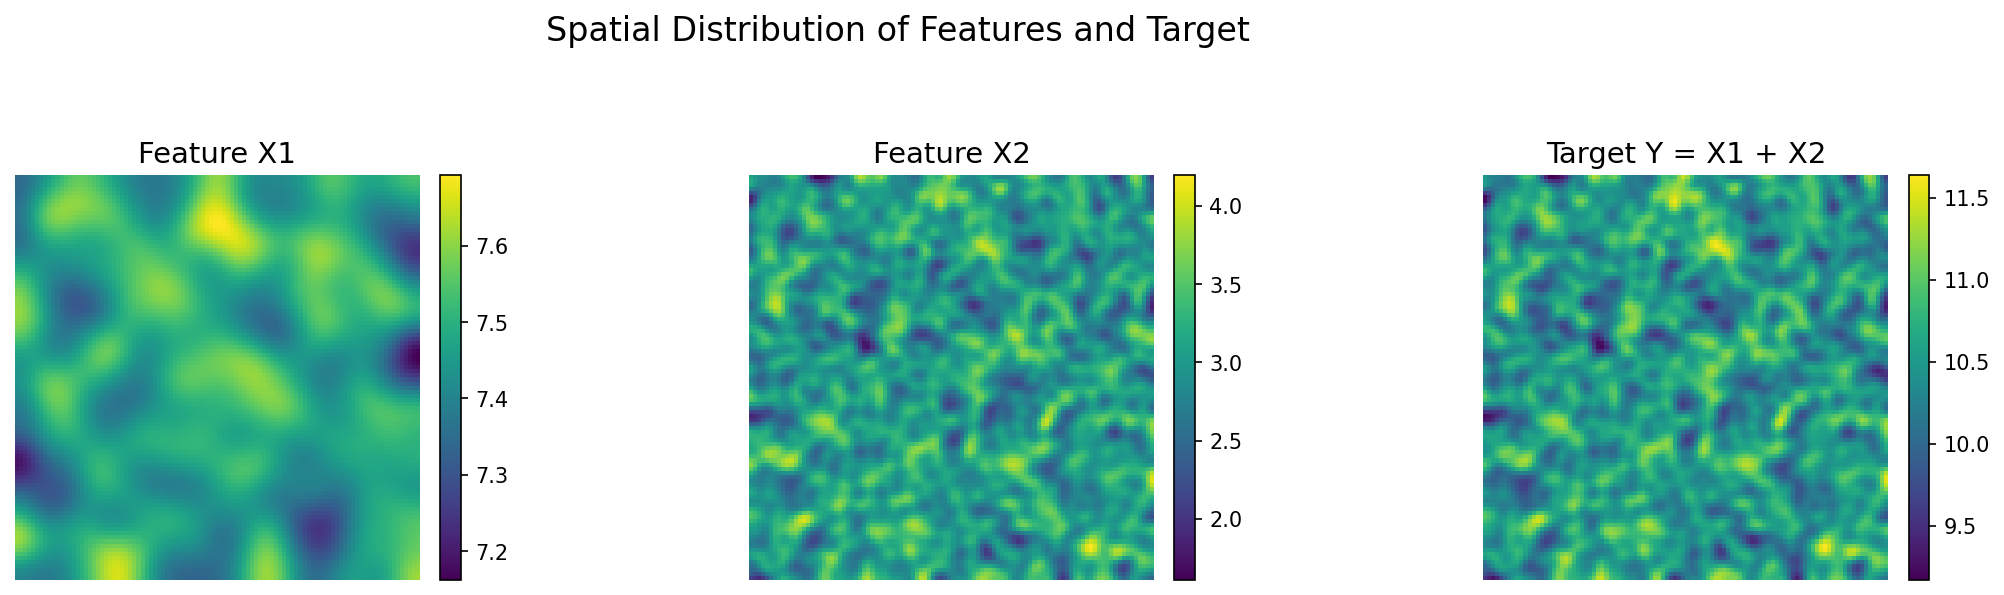

In [ ]:
# -------------------------------
# 网格
# -------------------------------
grid_size = 100
x = np.linspace(0, 1, grid_size)
y = np.linspace(0, 1, grid_size)
X_grid, Y_grid = np.meshgrid(x, y)
coords = np.stack([X_grid.ravel(), Y_grid.ravel()], axis=1)
base_X_coords = pd.DataFrame(coords, columns=["x_coord", "y_coord"])

# -------------------------------
# 空间特征 X1, X2
# -------------------------------
np.random.seed(42)
X1 = gaussian_filter(
    np.random.uniform(5, 10, size=(grid_size, grid_size)), sigma=5
).ravel()
X2 = gaussian_filter(
    np.random.uniform(0, 6, size=(grid_size, grid_size)), sigma=1.5
).ravel()

true_y = X1 + X2

df_coord_to_feat = base_X_coords.copy()
df_coord_to_feat["X1"] = X1
df_coord_to_feat["X2"] = X2
# =====================================================
# 可视化 X1 / X2 / Y（论文级）
# =====================================================

X1_grid = X1.reshape(grid_size, grid_size)
X2_grid = X2.reshape(grid_size, grid_size)
Y_grid = true_y.reshape(grid_size, grid_size)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=150)
ax = axes.ravel()

# 统一 colormap
cmap = "viridis"

# X1
im0 = ax[0].imshow(X1_grid, cmap=cmap)
ax[0].set_title("Feature X1", fontsize=14)
fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.03)

# X2
im1 = ax[1].imshow(X2_grid, cmap=cmap)
ax[1].set_title("Feature X2", fontsize=14)
fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.03)

# Y
im2 = ax[2].imshow(Y_grid, cmap=cmap)
ax[2].set_title("Target Y = X1 + X2", fontsize=14)
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.03)

# 美化
for a in ax:
    a.axis("off")

fig.suptitle("Spatial Distribution of Features and Target", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.9])

# 保存为 Illustrator 可编辑 PDF
plt.savefig("spatial_features_X1_X2_Y.pdf", format="pdf")
plt.show()


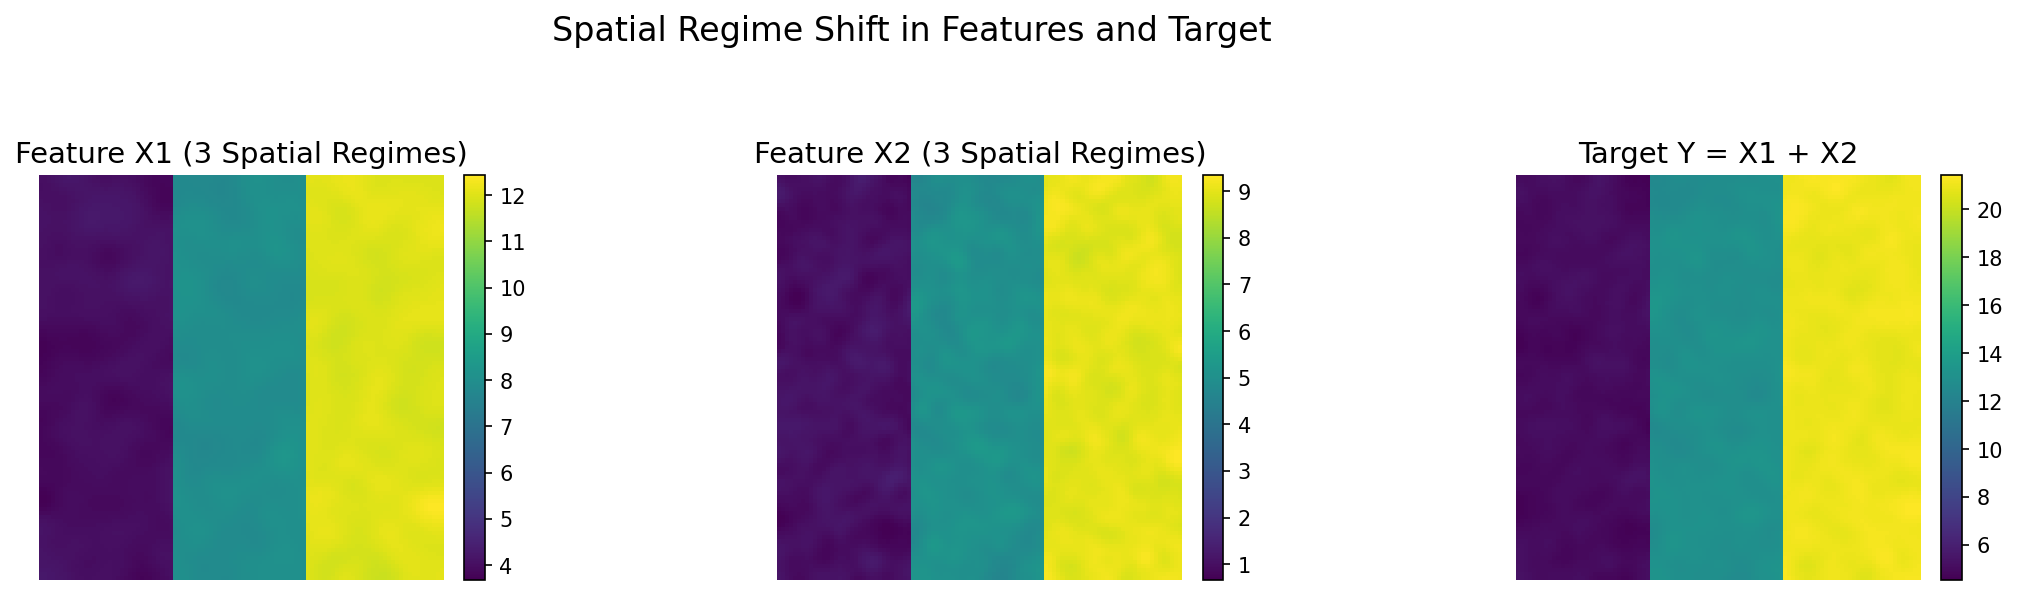

In [ ]:
# ## 突变类型的变量

# # =====================================================
# # 0. 依赖与全局设置（Illustrator 可编辑字体）
# # =====================================================
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.ndimage import gaussian_filter
# import matplotlib as mpl

# mpl.rcParams["pdf.fonttype"] = 42      # TrueType（AI 可编辑）
# mpl.rcParams["ps.fonttype"] = 42
# mpl.rcParams["font.family"] = "sans-serif"
# mpl.rcParams["font.sans-serif"] = ["Arial"]  # 没有可换 Helvetica / DejaVu Sans
# mpl.rcParams["axes.unicode_minus"] = False


# # =====================================================
# # 1. 构建规则网格
# # =====================================================
# grid_size = 100
# x = np.linspace(0, 1, grid_size)
# y = np.linspace(0, 1, grid_size)
# X_grid, Y_grid = np.meshgrid(x, y)

# coords = np.stack([X_grid.ravel(), Y_grid.ravel()], axis=1)
# base_X_coords = pd.DataFrame(coords, columns=["x_coord", "y_coord"])


# # =====================================================
# # 2. 构造具有“空间突变（regime shift）”的 X1 / X2
# #    —— 从左到右 3 个不同 mean
# # =====================================================
# np.random.seed(42)

# # --- regime 划分（沿 x 方向）---
# regime_1 = X_grid < 1 / 3
# regime_2 = (X_grid >= 1 / 3) & (X_grid < 2 / 3)
# regime_3 = X_grid >= 2 / 3

# # -------------------------------
# # X1：三个 regime，不同均值
# # -------------------------------
# X1_base = np.zeros((grid_size, grid_size))
# X1_base[regime_1] = 4     # 左区
# X1_base[regime_2] = 8     # 中区
# X1_base[regime_3] = 12    # 右区

# X1_noise = gaussian_filter(
#     np.random.normal(0, 1.0, size=(grid_size, grid_size)),
#     sigma=3
# )

# X1 = (X1_base + X1_noise).ravel()

# # -------------------------------
# # X2：也有 regime，但数值结构不同
# # -------------------------------
# X2_base = np.zeros((grid_size, grid_size))
# X2_base[regime_1] = 1
# X2_base[regime_2] = 5
# X2_base[regime_3] = 9

# X2_noise = gaussian_filter(
#     np.random.normal(0, 0.8, size=(grid_size, grid_size)),
#     sigma=2
# )

# X2 = (X2_base + X2_noise).ravel()


# # =====================================================
# # 3. 构造目标变量 Y
# # =====================================================
# true_y = X1 + X2

# df_coord_to_feat = base_X_coords.copy()
# df_coord_to_feat["X1"] = X1
# df_coord_to_feat["X2"] = X2


# # =====================================================
# # 4. 论文级可视化（X1 / X2 / Y）
# # =====================================================
# X1_grid_plot = X1.reshape(grid_size, grid_size)
# X2_grid_plot = X2.reshape(grid_size, grid_size)
# Y_grid_plot = true_y.reshape(grid_size, grid_size)

# fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=150)
# ax = axes.ravel()

# cmap = "viridis"

# # ---- X1 ----
# im0 = ax[0].imshow(X1_grid_plot, cmap=cmap)
# ax[0].set_title("Feature X1 (3 Spatial Regimes)", fontsize=14)
# fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.03)

# # ---- X2 ----
# im1 = ax[1].imshow(X2_grid_plot, cmap=cmap)
# ax[1].set_title("Feature X2 (3 Spatial Regimes)", fontsize=14)
# fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.03)

# # ---- Y ----
# im2 = ax[2].imshow(Y_grid_plot, cmap=cmap)
# ax[2].set_title("Target Y = X1 + X2", fontsize=14)
# fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.03)

# # 美化
# for a in ax:
#     a.axis("off")

# fig.suptitle("Spatial Regime Shift in Features and Target", fontsize=16)
# plt.tight_layout(rect=[0, 0, 1, 0.9])

# # 保存为 Illustrator 可编辑 PDF
# plt.savefig("spatial_regime_X1_X2_Y.pdf", format="pdf")
# plt.show()


In [ ]:
(
    X_spatial_train, X_spatial_temp,
    X_aspatial_train, X_aspatial_temp,
    y_train, y_temp,
    loc_train, loc_temp
) = train_test_split(
    base_X_coords,
    np.vstack([X1, X2]).T,
    true_y,
    base_X_coords,
    train_size=0.8,
    random_state=42
)

(
    X_spatial_val, X_spatial_test,
    X_aspatial_val, X_aspatial_test,
    y_val, y_test,
    loc_val, loc_test
) = train_test_split(
    X_spatial_temp,
    X_aspatial_temp,
    y_temp,
    loc_temp,
    train_size=0.5,
    random_state=42
)
noise_sigma_list = [0.1, 0.5, 1, 1.5, 2, 2.5, 3, 5, 10]
noise_std_list = [1.0]


In [ ]:
import matplotlib as mpl

mpl.rcParams["pdf.fonttype"] = 42      # TrueType 字体（AI 可编辑）
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial"]  # Illustrator 友好
mpl.rcParams["axes.unicode_minus"] = False


In [ ]:
for noise_sigma in tqdm(noise_sigma_list, desc="Noise Sigma"):
    for noise_std in noise_std_list:

        print(f"\n===== sigma={noise_sigma}, std={noise_std} =====")

        # =====================================================
        # 4.1 生成两种噪声
        # =====================================================

        # (A) 地理距离噪声
        df_noise_spatial = create_coord_noise_df(
            X_coords=base_X_coords,
            grid_size=grid_size,
            noise_std=noise_std,
            sigma=noise_sigma,
            seed=None
        )

        # (B) 特征空间噪声
        df_noise_feature = create_coord_noise_df(
            X_coords=base_X_coords,
            grid_size=grid_size,
            noise_std=noise_std,
            feature_space_cluster=True,
            X_features=np.vstack([X1, X2]).T,
            cluster_center=(7, 2),
            cluster_width=0.3 * noise_sigma,
            seed=None
        )

        # =====================================================
        # 4.2 定义预测函数（两种噪声）
        # =====================================================
        predict_spatial = lambda X_df: biased_model_predict(
            X_df, df_coord_to_feat, df_noise_spatial
        )

        predict_feature = lambda X_df: biased_model_predict(
            X_df, df_coord_to_feat, df_noise_feature
        )

        # =====================================================
        # 4.3 GeoCP + GeoSIMCP（Spatial Noise）
        # =====================================================
        geocp_spatial = GeoConformalSpatialRegression(
            predict_f=predict_spatial,
            miscoverage_level=0.1,
            bandwidth=0.1,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            y_calib=y_val,
            X_test=base_X_coords.copy(),
            y_test=true_y
        )
        res_geocp_spatial = geocp_spatial.analyze()

        geosimcp_spatial = GeoSIMConformalSpatialRegression(
            predict_f=predict_spatial,
            miscoverage_level=0.1,
            bandwidth=0.1,
            lambda_weight=0.0,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            X_test=base_X_coords.copy(),
            X_calib_weight=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
            X_test_weight=pd.DataFrame(np.vstack([X1, X2]).T, columns=["X1", "X2"]),
            y_calib=y_val,
            y_test=true_y
        )
        res_geosimcp_spatial = geosimcp_spatial.analyze()

        # =====================================================
        # 4.4 GeoCP + GeoSIMCP（Feature Noise）
        # =====================================================
        geocp_feature = GeoConformalSpatialRegression(
            predict_f=predict_feature,
            miscoverage_level=0.1,
            bandwidth=0.1,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            y_calib=y_val,
            X_test=base_X_coords.copy(),
            y_test=true_y
        )
        res_geocp_feature = geocp_feature.analyze()

        geosimcp_feature = GeoSIMConformalSpatialRegression(
            predict_f=predict_feature,
            miscoverage_level=0.1,
            bandwidth=0.1,
            lambda_weight=0.0,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            X_test=base_X_coords.copy(),
            X_calib_weight=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
            X_test_weight=pd.DataFrame(np.vstack([X1, X2]).T, columns=["X1", "X2"]),
            y_calib=y_val,
            y_test=true_y
        )
        res_geosimcp_feature = geosimcp_feature.analyze()

        # =====================================================
        # 4.5 可视化（6 张图 + 每个子图 colorbar + 保存 PDF）
        # =====================================================

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        ax = axes.ravel()

        # 数据准备
        noise_spatial = np.abs(df_noise_spatial["noise"].values).reshape(grid_size, grid_size)
        noise_feature = np.abs(df_noise_feature["noise"].values).reshape(grid_size, grid_size)

        geo_unc_geocp_spatial = np.array(res_geocp_spatial.geo_uncertainty).reshape(grid_size, grid_size)
        geo_unc_geosimcp_spatial = np.array(res_geosimcp_spatial.geo_uncertainty).reshape(grid_size, grid_size)
        geo_unc_geocp_feature = np.array(res_geocp_feature.geo_uncertainty).reshape(grid_size, grid_size)
        geo_unc_geosimcp_feature = np.array(res_geosimcp_feature.geo_uncertainty).reshape(grid_size, grid_size)

        # 为公平对比，统一 color scale（可选，但强烈推荐）
        vmax_noise = max(noise_spatial.max(), noise_feature.max())
        vmax_unc = max(
            geo_unc_geocp_spatial.max(),
            geo_unc_geosimcp_spatial.max(),
            geo_unc_geocp_feature.max(),
            geo_unc_geosimcp_feature.max()
        )

        # --- 第一行：Spatial Noise ---
        im0 = ax[0].imshow(noise_spatial, cmap="coolwarm", vmin=0, vmax=vmax_noise)
        ax[0].set_title("Abs Spatial Noise", fontsize=14)
        fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.02)

        im1 = ax[1].imshow(geo_unc_geocp_spatial, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[1].set_title("GeoCP (Spatial Noise)", fontsize=14)
        fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.02)

        im2 = ax[2].imshow(geo_unc_geosimcp_spatial, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[2].set_title("GeoSIMCP (Spatial Noise)", fontsize=14)
        fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.02)

        # --- 第二行：Feature Noise ---
        im3 = ax[3].imshow(noise_feature, cmap="coolwarm", vmin=0, vmax=vmax_noise)
        ax[3].set_title("Abs Feature-space Noise", fontsize=14)
        fig.colorbar(im3, ax=ax[3], fraction=0.046, pad=0.02)

        im4 = ax[4].imshow(geo_unc_geocp_feature, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[4].set_title("GeoCP (Feature Noise)", fontsize=14)
        fig.colorbar(im4, ax=ax[4], fraction=0.046, pad=0.02)

        im5 = ax[5].imshow(geo_unc_geosimcp_feature, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[5].set_title("GeoSIMCP (Feature Noise)", fontsize=14)
        fig.colorbar(im5, ax=ax[5], fraction=0.046, pad=0.02)

        # 统一关闭坐标轴
        for a in ax:
            a.axis("off")

        # 总标题
        fig.suptitle(
            f"Noise Regimes Comparison (σ = {noise_sigma}, std = {noise_std})",
            fontsize=18
        )

        plt.tight_layout(rect=[0, 0, 1, 0.94])

        # =====================================================
        # 保存为 Illustrator 可编辑的 PDF
        # =====================================================
        save_path = f"noise_regime_comparison_sigma_{noise_sigma}.pdf"
        plt.savefig(save_path, format="pdf")
        plt.close(fig)

        print(f"✅ Figure saved: {save_path}")


Noise Sigma:   0%|          | 0/9 [00:00<?, ?it/s]


===== sigma=0.1, std=1.0 =====


Noise Sigma:  11%|█         | 1/9 [00:07<00:56,  7.04s/it]

✅ Figure saved: noise_regime_comparison_sigma_0.1.pdf

===== sigma=0.5, std=1.0 =====


Noise Sigma:  22%|██▏       | 2/9 [00:15<00:54,  7.79s/it]

...

✅ Figure saved: noise_regime_comparison_sigma_3.pdf

===== sigma=5, std=1.0 =====


Noise Sigma:  89%|████████▉ | 8/9 [01:08<00:08,  8.50s/it]

✅ Figure saved: noise_regime_comparison_sigma_5.pdf

===== sigma=10, std=1.0 =====


Noise Sigma: 100%|██████████| 9/9 [01:17<00:00,  8.61s/it]

✅ Figure saved: noise_regime_comparison_sigma_10.pdf


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity"
os.makedirs(SAVE_DIR, exist_ok=True)


In [ ]:
for noise_sigma in tqdm(noise_sigma_list, desc="Noise Sigma"):
    for noise_std in noise_std_list:

        print(f"\n===== sigma={noise_sigma}, std={noise_std} =====")

        # =====================================================
        # 4.1 生成两种噪声
        # =====================================================
        df_noise_spatial = create_coord_noise_df(
            X_coords=base_X_coords,
            grid_size=grid_size,
            noise_std=noise_std,
            sigma=noise_sigma,
            seed=None
        )

        df_noise_feature = create_coord_noise_df(
            X_coords=base_X_coords,
            grid_size=grid_size,
            noise_std=noise_std,
            feature_space_cluster=True,
            X_features=np.vstack([X1, X2]).T,
            cluster_center=(7, 2),
            cluster_width=0.3 * noise_sigma,
            seed=None
        )

        # =====================================================
        # 4.2 预测函数
        # =====================================================
        predict_spatial = lambda X_df: biased_model_predict(
            X_df, df_coord_to_feat, df_noise_spatial
        )
        predict_feature = lambda X_df: biased_model_predict(
            X_df, df_coord_to_feat, df_noise_feature
        )

        # =====================================================
        # 4.3 模型（Spatial Noise）
        # =====================================================
        geocp_spatial = GeoConformalSpatialRegression(
            predict_f=predict_spatial,
            miscoverage_level=0.1,
            bandwidth=0.1,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            y_calib=y_val,
            X_test=base_X_coords.copy(),
            y_test=true_y
        )
        res_geocp_spatial = geocp_spatial.analyze()

        geosimcp_spatial = GeoSIMConformalSpatialRegression(
            predict_f=predict_spatial,
            miscoverage_level=0.1,
            bandwidth=0.1,
            lambda_weight=0.0,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            X_test=base_X_coords.copy(),
            X_calib_weight=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
            X_test_weight=pd.DataFrame(np.vstack([X1, X2]).T, columns=["X1", "X2"]),
            y_calib=y_val,
            y_test=true_y
        )
        res_geosimcp_spatial = geosimcp_spatial.analyze()

        # =====================================================
        # 4.4 模型（Feature Noise）
        # =====================================================
        geocp_feature = GeoConformalSpatialRegression(
            predict_f=predict_feature,
            miscoverage_level=0.1,
            bandwidth=0.1,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            y_calib=y_val,
            X_test=base_X_coords.copy(),
            y_test=true_y
        )
        res_geocp_feature = geocp_feature.analyze()

        geosimcp_feature = GeoSIMConformalSpatialRegression(
            predict_f=predict_feature,
            miscoverage_level=0.1,
            bandwidth=0.1,
            lambda_weight=0.0,
            coord_calib=loc_val.values,
            coord_test=base_X_coords.values,
            X_calib=loc_val.copy(),
            X_test=base_X_coords.copy(),
            X_calib_weight=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
            X_test_weight=pd.DataFrame(np.vstack([X1, X2]).T, columns=["X1", "X2"]),
            y_calib=y_val,
            y_test=true_y
        )
        res_geosimcp_feature = geosimcp_feature.analyze()

        # =====================================================
        # 4.5 数据准备（含预测误差）
        # =====================================================
        noise_spatial = np.abs(df_noise_spatial["noise"].values).reshape(grid_size, grid_size)
        noise_feature = np.abs(df_noise_feature["noise"].values).reshape(grid_size, grid_size)

        y_pred_spatial = predict_spatial(base_X_coords)
        y_pred_feature = predict_feature(base_X_coords)

        error_spatial = np.abs(true_y - y_pred_spatial).reshape(grid_size, grid_size)
        error_feature = np.abs(true_y - y_pred_feature).reshape(grid_size, grid_size)

        geo_unc_geocp_spatial = np.array(res_geocp_spatial.geo_uncertainty).reshape(grid_size, grid_size)
        geo_unc_geosimcp_spatial = np.array(res_geosimcp_spatial.geo_uncertainty).reshape(grid_size, grid_size)
        geo_unc_geocp_feature = np.array(res_geocp_feature.geo_uncertainty).reshape(grid_size, grid_size)
        geo_unc_geosimcp_feature = np.array(res_geosimcp_feature.geo_uncertainty).reshape(grid_size, grid_size)

        vmax_noise = max(noise_spatial.max(), noise_feature.max())
        vmax_unc = max(
            geo_unc_geocp_spatial.max(),
            geo_unc_geosimcp_spatial.max(),
            geo_unc_geocp_feature.max(),
            geo_unc_geosimcp_feature.max()
        )
        vmax_err = max(error_spatial.max(), error_feature.max())

        # =====================================================
        # 4.6 可视化（8 张图）
        # =====================================================
        fig, axes = plt.subplots(2, 4, figsize=(24, 10))
        ax = axes.ravel()

        # ---- Spatial noise ----
        im0 = ax[0].imshow(noise_spatial, cmap="coolwarm", vmin=0, vmax=vmax_noise)
        ax[0].set_title("Abs Spatial Noise")
        fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.02)

        im1 = ax[1].imshow(error_spatial, cmap="magma", vmin=0, vmax=vmax_err)
        ax[1].set_title("Prediction Error (Spatial Noise)")
        fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.02)

        im2 = ax[2].imshow(geo_unc_geocp_spatial, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[2].set_title("GeoCP Uncertainty (Spatial)")
        fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.02)

        im3 = ax[3].imshow(geo_unc_geosimcp_spatial, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[3].set_title("GeoSIMCP Uncertainty (Spatial)")
        fig.colorbar(im3, ax=ax[3], fraction=0.046, pad=0.02)

        # ---- Feature noise ----
        im4 = ax[4].imshow(noise_feature, cmap="coolwarm", vmin=0, vmax=vmax_noise)
        ax[4].set_title("Abs Feature Noise")
        fig.colorbar(im4, ax=ax[4], fraction=0.046, pad=0.02)

        im5 = ax[5].imshow(error_feature, cmap="magma", vmin=0, vmax=vmax_err)
        ax[5].set_title("Prediction Error (Feature Noise)")
        fig.colorbar(im5, ax=ax[5], fraction=0.046, pad=0.02)

        im6 = ax[6].imshow(geo_unc_geocp_feature, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[6].set_title("GeoCP Uncertainty (Feature)")
        fig.colorbar(im6, ax=ax[6], fraction=0.046, pad=0.02)

        im7 = ax[7].imshow(geo_unc_geosimcp_feature, cmap="coolwarm", vmin=0, vmax=vmax_unc)
        ax[7].set_title("GeoSIMCP Uncertainty (Feature)")
        fig.colorbar(im7, ax=ax[7], fraction=0.046, pad=0.02)

        for a in ax:
            a.axis("off")

        fig.suptitle(
            f"Noise Regimes & Prediction Error (σ={noise_sigma}, std={noise_std})",
            fontsize=18
        )
        plt.tight_layout(rect=[0, 0, 1, 0.93])

        # =====================================================
        # 保存 PDF
        # =====================================================
        save_path = os.path.join(
            SAVE_DIR, f"noise_regime_error_sigma_{noise_sigma}.pdf"
        )
        plt.savefig(save_path, format="pdf")
        plt.close(fig)

        print(f"✅ Figure saved to {save_path}")


Noise Sigma:   0%|          | 0/9 [00:00<?, ?it/s]


===== sigma=0.1, std=1.0 =====


Noise Sigma:  11%|█         | 1/9 [00:12<01:42, 12.75s/it]

✅ Figure saved to /content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/noise_regime_error_sigma_0.1.pdf

===== sigma=0.5, std=1.0 =====


Noise Sigma:  22%|██▏       | 2/9 [00:20<01:08,  9.85s/it]

...

✅ Figure saved to /content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/noise_regime_error_sigma_3.pdf

===== sigma=5, std=1.0 =====


Noise Sigma:  89%|████████▉ | 8/9 [01:14<00:09,  9.09s/it]

✅ Figure saved to /content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/noise_regime_error_sigma_5.pdf

===== sigma=10, std=1.0 =====


Noise Sigma: 100%|██████████| 9/9 [01:23<00:00,  9.25s/it]

✅ Figure saved to /content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/noise_regime_error_sigma_10.pdf


# GeoSIMCP with zhao

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# ===================================
# ✨ 1. interval_score
# ===================================
def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    return width + (2 / alpha) * (below + above)

# ===================================
# ✨ 2. GeoCP的bandwidth sweep
# ===================================
def bandwidth_grid_sweep_geocp(
    bandwidth_list,
    predict_f,
    X_val,
    X_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    noise_abs=None,
    alpha=0.1,
    coverage_threshold=0.9
):
    from GeoConformalSpatialRegression import GeoConformalSpatialRegression

    coverage_list = []
    uncertainty_list = []
    interval_score_list = []
    rmse_list = []
    r2_list = []

    for bw in bandwidth_list:
        model = GeoConformalSpatialRegression(
            predict_f=predict_f,
            miscoverage_level=alpha,
            bandwidth=bw,
            coord_calib=loc_val.values,
            coord_test=loc_test.values,
            X_calib=X_val,
            y_calib=y_val,
            X_test=X_test,
            y_test=y_test
        )

        result = model.analyze()
        coverage_list.append(result.coverage_probability)

        unc = np.array(result.geo_uncertainty)
        unc = unc[~np.isnan(unc)]
        uncertainty_list.append(np.mean(unc) if len(unc) > 0 else np.nan)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        interval_score_list.append(np.mean(score))

        if noise_abs is not None:
            geo_uncertainty = result.geo_uncertainty.reshape(noise_abs.shape)
            rmse_list.append(np.sqrt(mean_squared_error(noise_abs.flatten(), geo_uncertainty.flatten())))
            r2_list.append(r2_score(noise_abs.flatten(), geo_uncertainty.flatten()))
        else:
            rmse_list.append(np.nan)
            r2_list.append(np.nan)

    mask = np.array(coverage_list) >= coverage_threshold
    masked_score = np.where(mask, interval_score_list, np.inf)
    best_idx = np.argmin(masked_score)
    best_bw = bandwidth_list[best_idx]

    print(f"✅ GeoCP Optimal Parameters Summary:")
    print(f"  Best Bandwidth   = {best_bw:.3f}")
    print(f"  Coverage         = {coverage_list[best_idx]:.3f}")
    print(f"  Interval Score   = {interval_score_list[best_idx]:.3f}")
    print(f"  Mean Uncertainty = {uncertainty_list[best_idx]:.3f}")
    print(f"  RMSE             = {rmse_list[best_idx]:.3f}")
    print(f"  R²               = {r2_list[best_idx]:.3f}")

    return {
        'coverage': coverage_list[best_idx],
        'interval_score': interval_score_list[best_idx],
        'mean_uncertainty': uncertainty_list[best_idx],
        'rmse': rmse_list[best_idx],
        'r2': r2_list[best_idx],
        'nrmse': rmse_list[best_idx] / (noise_abs.max() - noise_abs.min()) if noise_abs is not None else np.nan,
        'best_bandwidth': best_bw
    }

# ===================================
# ✨ 3. GeoSIMCP Zhao的bandwidth × lambda sweep (加上打印)
# ===================================
def select_best_lambda_bandwidth(coverage_grid, score_grid, lambda_list, bandwidth_list, threshold=0.9):
    mask = coverage_grid >= threshold
    if np.any(mask):
        masked_score = np.where(mask, score_grid, np.inf)
        idx = np.unravel_index(np.nanargmin(masked_score), masked_score.shape)
    else:
        print("⚠️ No parameters meet coverage threshold, selecting from all candidates.")
        idx = np.unravel_index(np.nanargmin(score_grid), score_grid.shape)

    best_lambda = lambda_list[idx[1]]
    best_bandwidth = bandwidth_list[idx[0]]
    best_score = score_grid[idx]
    return best_lambda, best_bandwidth, best_score, idx

def geosimcp_bandwidth_lambda_grid_sweep(
    bandwidth_list,
    lambda_list,
    predict_f,
    X_spatial_val,
    X_spatial_test,
    X_aspatial_val,
    X_aspatial_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    noise_abs=None,
    alpha=0.1,
    coverage_threshold=0.9
):
    from GeoSIMCPzhao import GeoSIMCPzhao

    coverage_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    uncertainty_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    interval_score_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    rmse_grid = np.full_like(interval_score_grid, np.nan)
    r2_grid = np.full_like(interval_score_grid, np.nan)

    for i, bw in enumerate(bandwidth_list):
        for j, lam in enumerate(lambda_list):
            try:
                model = GeoSIMCPzhao(
                    predict_f=predict_f,
                    miscoverage_level=alpha,
                    bandwidth=bw,
                    coord_calib=loc_val.values,
                    coord_test=loc_test.values,
                    X_calib=X_spatial_val,
                    X_test=X_spatial_test,
                    y_calib=y_val,
                    y_test=y_test,
                    X_calib_weight=X_aspatial_val,
                    X_test_weight=X_aspatial_test,
                    lambda_weight=lam
                )
                result = model.analyze()

                coverage_grid[i, j] = result.coverage_probability
                uncertainty_grid[i, j] = np.mean(result.geo_uncertainty)

                lower, upper, y_true = np.array(result.lower_bound), np.array(result.upper_bound), np.array(y_test)
                score = interval_score(y_true, lower, upper, alpha=alpha)
                interval_score_grid[i, j] = np.mean(score)

                if noise_abs is not None:
                    geo_uncertainty = result.geo_uncertainty.reshape(noise_abs.shape)
                    rmse_grid[i, j] = np.sqrt(mean_squared_error(noise_abs.flatten(), geo_uncertainty.flatten()))
                    r2_grid[i, j] = r2_score(noise_abs.flatten(), geo_uncertainty.flatten())

            except Exception as e:
                print(f"❌ Model failed at bandwidth={bw:.3f}, lambda={lam:.3f}")
                print(f"   Error: {str(e)}")
                continue

    best_lambda, best_bw, best_score, idx = select_best_lambda_bandwidth(
        coverage_grid, interval_score_grid, lambda_list, bandwidth_list, threshold=coverage_threshold
    )

    print("✅ GeoSIMCP Optimal Parameters Summary:")
    print(f"  Best Bandwidth   = {best_bw:.3f}")
    print(f"  Best Lambda      = {best_lambda:.3f}")
    print(f"  Coverage         = {coverage_grid[idx]:.3f}")
    print(f"  Interval Score   = {best_score:.3f}")
    print(f"  Mean Uncertainty = {uncertainty_grid[idx]:.3f}")
    if noise_abs is not None:
        print(f"  RMSE             = {rmse_grid[idx]:.3f}")
        print(f"  R²               = {r2_grid[idx]:.3f}")

    return {
        'coverage': coverage_grid[idx],
        'interval_score': best_score,
        'mean_uncertainty': uncertainty_grid[idx],
        'rmse': rmse_grid[idx],
        'r2': r2_grid[idx],
        'nrmse': rmse_grid[idx] / (noise_abs.max() - noise_abs.min()) if noise_abs is not None else np.nan,
        'best_bandwidth': best_bw,
        'best_lambda': best_lambda
    }

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm



def batch_run_geocp_geosimcp(
    noise_sigma_list=None,
    noise_std_list=None,
    grid_size=100,
    base_X_coords=None,
    X1=None,
    X2=None,
    true_y=None,
    df_coord_to_feat=None,
    create_coord_noise_df=None,
    biased_model_predict=None,
    bandwidth_list_geocp=None,
    bandwidth_list_geosimcp=None,
    lambda_list_geosimcp=None,
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="geo_cp_vs_simcp_batch",
    feature_space_noise=False,
    run_geocp=True,
    run_geosimcp=True
):
    results = []

    if noise_sigma_list is None:
        noise_sigma_list = [3.0]
    if noise_std_list is None:
        noise_std_list = [1.0]

    for noise_sigma in tqdm(noise_sigma_list, desc="Sigma Loop"):
        for noise_std in tqdm(noise_std_list, desc="STD Loop", leave=False):

            if feature_space_noise:
                X_features = np.vstack([X1, X2]).T
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    feature_space_cluster=True,
                    X_features=X_features,
                    cluster_center=(7, 2),
                    cluster_width=0.5,
                    seed=42
                )
            else:
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    seed=42
                )

            predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)
            X_features = np.vstack([X1, X2]).T
            noise_abs = np.abs(df_coord_to_noise["noise"].values.reshape(grid_size, grid_size))

            if run_geocp:
                geocp_metrics = bandwidth_grid_sweep_geocp(
                    bandwidth_list=bandwidth_list_geocp,
                    predict_f=predict_f,
                    X_val=loc_val,
                    X_test=base_X_coords,
                    y_val=y_val,
                    y_test=true_y,
                    loc_val=loc_val,
                    loc_test=base_X_coords,
                    noise_abs=noise_abs,
                    alpha=alpha,
                    coverage_threshold=coverage_threshold
                )

                results.append({
                    'noise_sigma': noise_sigma,
                    'noise_std': noise_std,
                    'method': 'GeoCP',
                    **geocp_metrics
                })

            if run_geosimcp:
                geosimcp_metrics = geosimcp_bandwidth_lambda_grid_sweep(
                    bandwidth_list=bandwidth_list_geosimcp,
                    lambda_list=lambda_list_geosimcp,
                    predict_f=predict_f,
                    X_spatial_val=loc_val,
                    X_spatial_test=base_X_coords,
                    X_aspatial_val=pd.DataFrame(X_aspatial_val, columns=["X1", "X2"]),
                    X_aspatial_test=pd.DataFrame(X_features, columns=["X1", "X2"]),
                    y_val=y_val,
                    y_test=true_y,
                    loc_val=loc_val,
                    loc_test=base_X_coords,
                    noise_abs=noise_abs,
                    alpha=alpha,
                    coverage_threshold=coverage_threshold
                )

                results.append({
                    'noise_sigma': noise_sigma,
                    'noise_std': noise_std,
                    'method': 'GeoSIMCP',
                    **geosimcp_metrics
                })

    results_df = pd.DataFrame(results)
    results_df.to_csv(f"{save_prefix}_metrics.csv", index=False)
    print(f"✅ All results saved to {save_prefix}_metrics.csv")

    return results_df



def plot_batch_results(
    results_df,
    save_prefix="geo_cp_vs_simcp_batch",
    x_axis="noise_std",
    fixed_value=None,
    fixed_param="noise_sigma"
):
    """
    Plot results of batch experiments.
    Automatically handles missing values.
    """
    indicators = ['coverage', 'interval_score', 'mean_uncertainty', 'rmse', 'r2']

    for indicator in indicators:
        plt.figure(figsize=(6, 4), dpi=150)

        for method in results_df['method'].unique():
            subset = results_df[results_df['method'] == method]
            if fixed_value is not None:
                subset = subset[subset[fixed_param] == fixed_value]

            subset = subset.sort_values(by=x_axis)

            if indicator in subset.columns:
                plt.plot(subset[x_axis], subset[indicator], label=method, marker='o')

        plt.title(f"{indicator} vs {x_axis.replace('_', ' ').title()}")
        plt.xlabel(x_axis.replace('_', ' ').title())
        plt.ylabel(indicator)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        save_name = f"{save_prefix}_{indicator}_x-{x_axis}"
        if fixed_value is not None:
            save_name += f"_fixed-{fixed_param}-{fixed_value}"

        plt.savefig(f"{save_name}.pdf")
        plt.show()


STD Loop:   0%|          | 0/18 [00:00<?, ?it/s]<ipython-input-41-55d784ad1848>:192: RuntimeWarning: invalid value encountered in scalar divide
  'nrmse': rmse_grid[idx] / (noise_abs.max() - noise_abs.min()) if noise_abs is not None else np.nan,

STD Loop:   6%|▌         | 1/18 [02:08<36:30, 128.88s/it]

✅ GeoSIMCP Optimal Parameters Summary:
  Best Bandwidth   = 0.100
  Best Lambda      = 0.000
  Coverage         = 1.000
  Interval Score   = 0.000
  Mean Uncertainty = 0.000
  RMSE             = 0.000
  R²               = 1.000



STD Loop:  11%|█         | 2/18 [04:38<37:34, 140.93s/it]

⚠️ No parameters meet coverage threshold, selecting from all candidates.
✅ GeoSIMCP Optimal Parameters Summary:
  Best Bandwidth   = 0.744
  Best Lambda      = 0.400
  Coverage         = 0.895
  Interval Score   = 0.041
  Mean Uncertainty = 0.016
  RMSE             = 0.010
  R²               = -1.829



STD Loop:  17%|█▋        | 3/18 [07:05<35:54, 143.64s/it]

...

✅ GeoSIMCP Optimal Parameters Summary:
  Best Bandwidth   = 0.100
  Best Lambda      = 1.000
  Coverage         = 0.958
  Interval Score   = 0.420
  Mean Uncertainty = 0.207
  RMSE             = 0.102
  R²               = -0.410



STD Loop:  94%|█████████▍| 17/18 [41:51<02:28, 148.90s/it]

✅ GeoSIMCP Optimal Parameters Summary:
  Best Bandwidth   = 0.100
  Best Lambda      = 1.000
  Coverage         = 0.958
  Interval Score   = 0.525
  Mean Uncertainty = 0.259
  RMSE             = 0.128
  R²               = -0.410



Sigma Loop: 100%|██████████| 9/9 [6:37:58<00:00, 2653.13s/it]

✅ GeoSIMCP Optimal Parameters Summary:
  Best Bandwidth   = 0.100
  Best Lambda      = 1.000
  Coverage         = 0.958
  Interval Score   = 1.051
  Mean Uncertainty = 0.517
  RMSE             = 0.255
  R²               = -0.410
✅ All results saved to geo_cp_vs_simcp_batch_metrics.csv


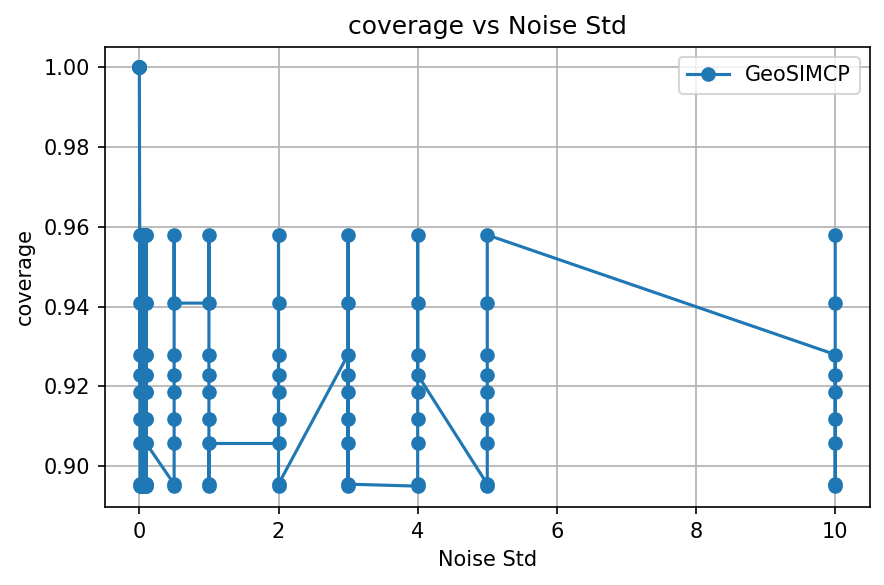

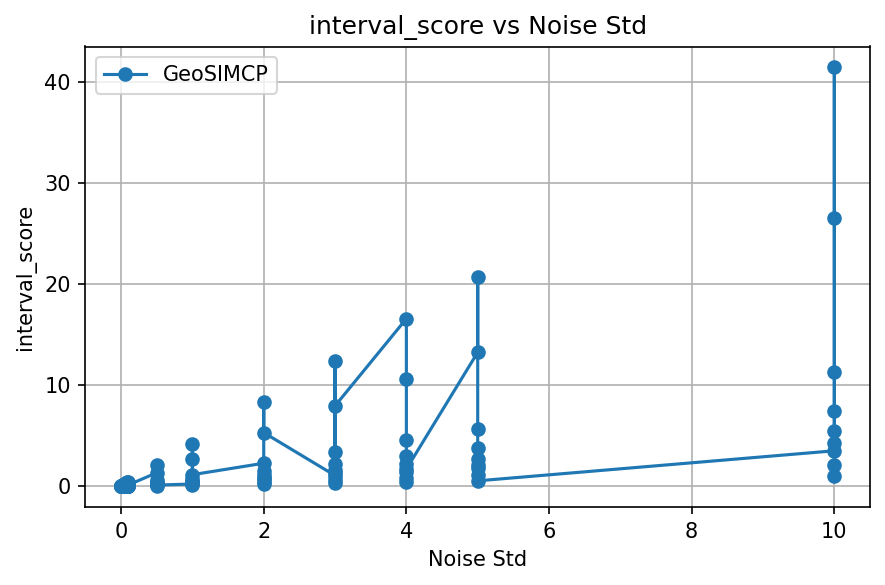

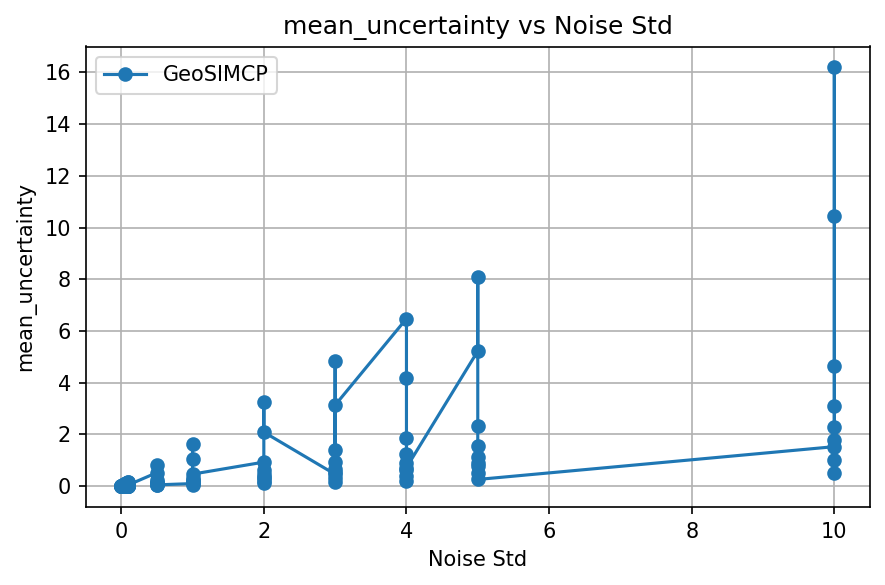

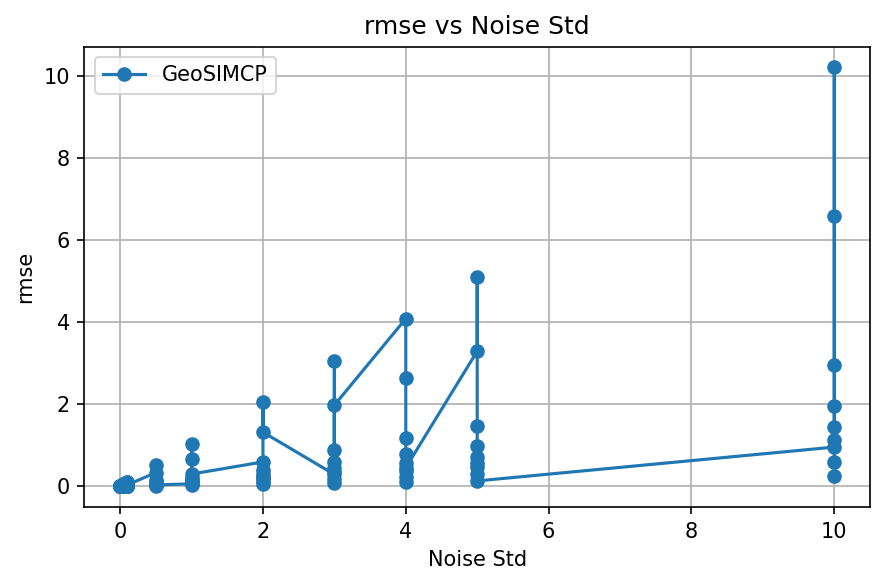

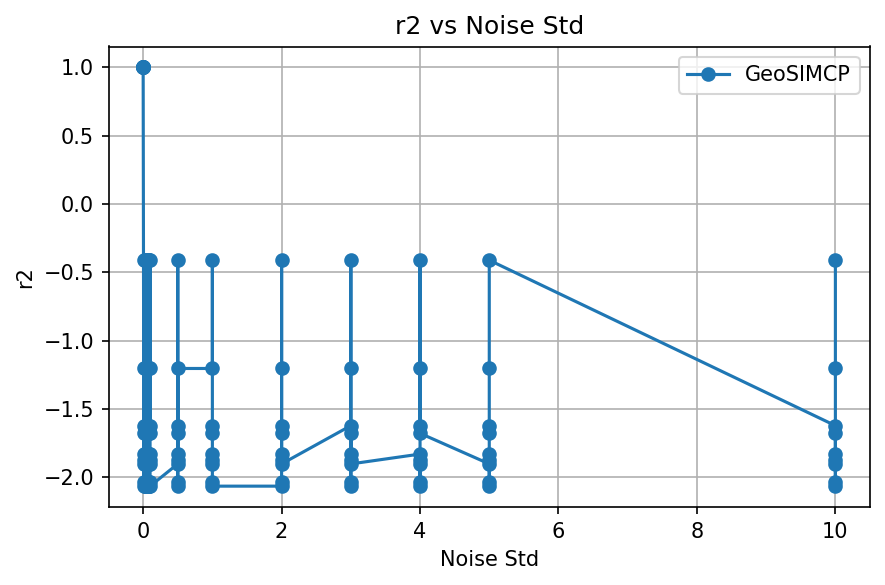

In [ ]:
results_df = batch_run_geocp_geosimcp(
    noise_std_list=[0,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.5,1,2,3,4,5,10],
    noise_sigma_list=[0.1,0.5,1,1.5,2,2.5,3,5,10],

    grid_size=100,
    base_X_coords=X_coords,
    X1=X1,
    X2=X2,
    true_y=true_y,
    df_coord_to_feat=df_coord_to_feat,
    create_coord_noise_df=create_coord_noise_df,
    biased_model_predict=biased_model_predict,
    bandwidth_list_geocp=np.linspace(0.1, 3, 10),
    bandwidth_list_geosimcp=np.linspace(0.1, 3, 10),
    lambda_list_geosimcp=np.linspace(0, 1, 6),
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="geo_cp_vs_simcp_batch",
    feature_space_noise=False,
    run_geocp=False,       # ✅ 新增：不跑GeoCP
    run_geosimcp=True      # ✅ 新增：只跑GeoSIMCP
)

# 保存CSV
results_df.to_csv(
    "/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study/geo_cp_vs_simcp_zhao_geonoise_with_sigma_0502.csv",
    index=False
)

# 绘图
plot_batch_results(
    results_df,
    save_prefix="geo_cp_vs_simcp_batch",
    x_axis="noise_std"
)


In [ ]:
results_df

NameError: name 'results_df' is not defined

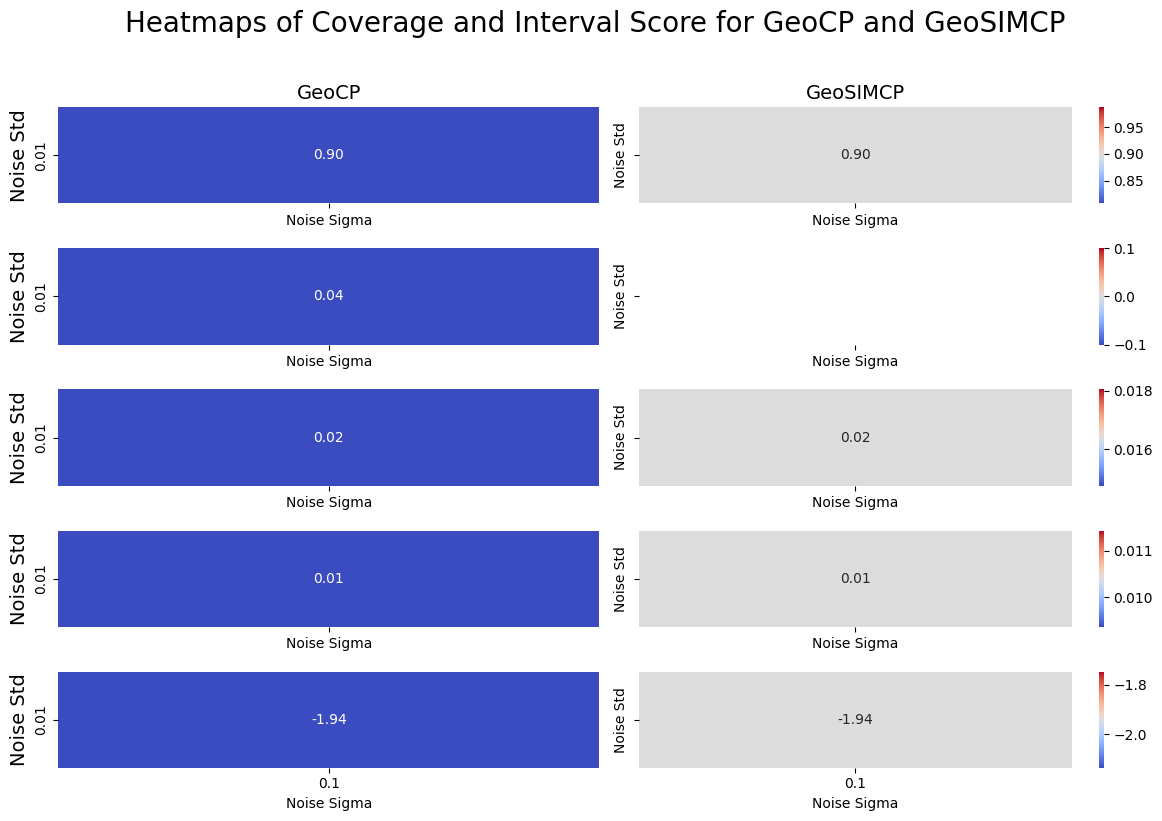

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["coverage", "interval_score", "mean_uncertainty", "rmse", "r2"]
methods = results_df['method'].unique()

fig, axes = plt.subplots(len(metrics), len(methods), figsize=(12, 8), sharex=True, sharey=True)

for row_idx, metric in enumerate(metrics):
    for col_idx, method in enumerate(methods):
        df_sub = results_df[results_df['method'] == method]
        pivot_table = df_sub.pivot_table(index="noise_std", columns="noise_sigma", values=metric)

        sns.heatmap(
            pivot_table,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[row_idx, col_idx],
            cbar=(col_idx == len(methods) - 1)
        )
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(f"{method}", fontsize=14)
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(f"{metric}", fontsize=14)

for ax in axes.flatten():
    ax.set_xlabel("Noise Sigma")
    ax.set_ylabel("Noise Std")

fig.suptitle("Heatmaps of Coverage and Interval Score for GeoCP and GeoSIMCP", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# 读取Excel文件
result_all = pd.read_csv("/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study/地理噪声/result_all.csv")

# 绘图函数
plot_batch_results(result_all, save_prefix="geo_cp_vs_simcp_batch", x_axis="noise_std")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study/地理噪声/result_all.csv'

In [ ]:
import pandas as pd

# 读取Excel文件
result_all = pd.read_excel("/content/drive/MyDrive/Research/0-Xiayin_research/4_GeoCP_with_geosimilarity/simulation study/results_all.xlsx")

# 绘图函数
plot_batch_results(result_all, save_prefix="geo_cp_vs_simcp_batch", x_axis="noise_std")

# LSCP

In [ ]:
!pip install quantile_forest


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 23.2 MB/s eta 0:00:00


In [ ]:
!pip install mapclassify


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 kB 3.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    score = width + (2 / alpha) * (below + above)
    score = np.where(np.isnan(score), 0.0, score)
    return score

def lscp_k_grid_sweep(
    k_list,
    model_spatial,
    X_val,
    X_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    alpha=0.1,
    coverage_threshold=0.9
):
    import LSCP  # ✅ 确保你已经有LSCP.py类

    coverage_list = []
    uncertainty_list = []
    interval_score_list = []
    rmse_list = []
    r2_list = []

    for k in k_list:
        model = LSCP.LSCP(
            predict_f=model_spatial.predict if model_spatial is not None else None,
            miscoverage_level=alpha,
            k=k,
            coord_calib=loc_val.values,
            coord_test=loc_test.values,
            x_calib=X_val,
            y_calib=y_val,
            x_test=X_test,
            y_test=y_test
        )

        result = model.analyze()

        coverage_list.append(result.coverage_probability)

        unc = np.array(result.geo_uncertainty)
        unc = unc[~np.isnan(unc)]
        uncertainty_list.append(np.mean(unc) if len(unc) > 0 else np.nan)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        score = score[~np.isnan(score)]
        interval_score_list.append(np.mean(score) if len(score) > 0 else np.nan)

        rmse = np.sqrt(mean_squared_error(y_true, result.predicted_value))
        r2 = r2_score(y_true, result.predicted_value)

        rmse_list.append(rmse)
        r2_list.append(r2)

    # ✅ 找最优 k
    mask = np.array(coverage_list) >= coverage_threshold
    masked_score = np.where(mask, interval_score_list, np.inf)
    best_idx = np.argmin(masked_score)
    best_k = k_list[best_idx]

    print(f"✅ LSCP Optimal Parameters Summary:")
    print(f"  Best k           = {best_k}")
    print(f"  Coverage         = {coverage_list[best_idx]:.3f}")
    print(f"  Interval Score   = {interval_score_list[best_idx]:.3f}")
    print(f"  Mean Uncertainty = {uncertainty_list[best_idx]:.3f}")
    print(f"  RMSE             = {rmse_list[best_idx]:.3f}")
    print(f"  R²               = {r2_list[best_idx]:.3f}")

    return {
        'coverage': coverage_list[best_idx],
        'interval_score': interval_score_list[best_idx],
        'mean_uncertainty': uncertainty_list[best_idx],
        'rmse': rmse_list[best_idx],
        'r2': r2_list[best_idx],
        'nrmse': rmse_list[best_idx] / (y_test.max() - y_test.min()) if y_test.max() != y_test.min() else np.nan,
        'best_k': best_k
    }


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

def batch_run_lscp(
    noise_sigma_list=None,
    noise_std_list=None,
    grid_size=100,
    base_X_coords=None,
    X1=None,
    X2=None,
    true_y=None,
    loc_val=None,            # ✅ 新增
    y_val=None,              # ✅ 新增
    df_coord_to_feat=None,
    create_coord_noise_df=None,
    biased_model_predict=None,
    k_list_lscp=None,
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="lscp_batch",
    feature_space_noise=False
):

    # ✅ 新增：强制把所有输入统一成DataFrame/Series
    base_X_coords = pd.DataFrame(base_X_coords, columns=["x_coord", "y_coord"]) if isinstance(base_X_coords, np.ndarray) else base_X_coords
    X1 = pd.Series(X1) if isinstance(X1, np.ndarray) else X1
    X2 = pd.Series(X2) if isinstance(X2, np.ndarray) else X2
    true_y = pd.Series(true_y) if isinstance(true_y, np.ndarray) else true_y
    loc_val = pd.DataFrame(loc_val, columns=["x_coord", "y_coord"]) if isinstance(loc_val, np.ndarray) else loc_val
    y_val = pd.Series(y_val) if isinstance(y_val, np.ndarray) else y_val


    results = []

    if noise_sigma_list is None:
        noise_sigma_list = [3.0]
    if noise_std_list is None:
        noise_std_list = [1.0]

    for noise_sigma in tqdm(noise_sigma_list, desc="Sigma Loop"):
        for noise_std in tqdm(noise_std_list, desc="STD Loop", leave=False):

            if feature_space_noise:
                X_features = np.vstack([X1, X2]).T
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    feature_space_cluster=True,
                    X_features=X_features,
                    cluster_center=(7, 2),
                    cluster_width=0.5,
                    seed=42
                )
            else:
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    seed=42
                )

            # ✅ 统一 predict_f
            predict_f = lambda X_df: biased_model_predict(X_df, df_coord_to_feat, df_coord_to_noise)

            # ✅ 保证所有输入是DataFrame或Series
            loc_val_df = pd.DataFrame(loc_val, columns=["x_coord", "y_coord"]) if isinstance(loc_val, np.ndarray) else loc_val
            base_X_coords_df = pd.DataFrame(base_X_coords, columns=["x_coord", "y_coord"]) if isinstance(base_X_coords, np.ndarray) else base_X_coords
            y_val_series = pd.Series(y_val) if isinstance(y_val, np.ndarray) else y_val
            true_y_series = pd.Series(true_y) if isinstance(true_y, np.ndarray) else true_y

            noise_abs = np.abs(df_coord_to_noise["noise"].values.reshape(grid_size, grid_size))
            X_features = np.vstack([X1, X2]).T

            # ✅ 调用 LSCP k sweep
            lscp_metrics = lscp_k_grid_sweep(
                k_list=k_list_lscp,
                predict_f=predict_f,
                X_val=loc_val_df,
                X_test=base_X_coords_df,
                y_val=y_val_series,
                y_test=true_y_series,
                loc_val=loc_val_df,
                loc_test=base_X_coords_df,
                noise_abs=noise_abs,
                alpha=alpha,
                coverage_threshold=coverage_threshold
            )

            # ✅ 保存本次实验的结果
            results.append({
                'noise_sigma': noise_sigma,
                'noise_std': noise_std,
                'method': 'LSCP',
                **lscp_metrics
            })

    # ✅ 汇总所有结果
    results_df = pd.DataFrame(results)
    results_df.to_csv(f"{save_prefix}_metrics.csv", index=False)
    print(f"✅ All LSCP results saved to {save_prefix}_metrics.csv")

    return results_df


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def save_and_plot_lscp_results(
    results_df,
    save_prefix="lscp_batch",
    save_dir="./outputs/lscp",  # ✅ 新增保存路径参数
    x_axis="noise_std",
    fixed_value=None,
    fixed_param="noise_sigma"
):
    """
    保存LSCP结果到指定目录，并绘制指标曲线
    """
    # ✅ 1. 确保保存目录存在
    os.makedirs(save_dir, exist_ok=True)

    # ✅ 2. 保存清理好的表格
    save_csv_path = os.path.join(save_dir, f"{save_prefix}_metrics_clean.csv")
    results_df.to_csv(save_csv_path, index=False)
    print(f"✅ 保存整理后的LSCP结果表到：{save_csv_path}")

    # ✅ 3. 开始画每个指标的图
    indicators = ['coverage', 'interval_score', 'mean_uncertainty', 'rmse', 'r2']

    for indicator in indicators:
        plt.figure(figsize=(6, 4), dpi=150)

        subset = results_df.copy()
        if fixed_value is not None:
            subset = subset[subset[fixed_param] == fixed_value]

        subset = subset.sort_values(by=x_axis)

        plt.plot(subset[x_axis], subset[indicator], label='LSCP', marker='o')

        plt.title(f"LSCP: {indicator.replace('_', ' ').title()} vs {x_axis.replace('_', ' ').title()}")
        plt.xlabel(x_axis.replace('_', ' ').title())
        plt.ylabel(indicator.replace('_', ' ').title())
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        # ✅ 4. 保存图片到指定目录
        save_fig_path = os.path.join(save_dir, f"{save_prefix}_{indicator}_x-{x_axis}")
        if fixed_value is not None:
            save_fig_path += f"_fixed-{fixed_param}-{fixed_value}"

        plt.savefig(f"{save_fig_path}.pdf")
        plt.show()


In [ ]:
results_lscp = batch_run_lscp(
    noise_sigma_list=[0.2],
    noise_std_list=[1.0],
    grid_size=100,
    base_X_coords=X_coords,
    X1=X1,
    X2=X2,
    true_y=true_y,
    loc_val=loc_val,
    y_val=y_val,
    df_coord_to_feat=df_coord_to_feat,
    create_coord_noise_df=create_coord_noise_df,
    biased_model_predict=biased_model_predict,
    k_list_lscp=[5, 8, 10, 15, 20],
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="lscp_batch",
    feature_space_noise=True,
    sample_rate=0.001  # ✅ 新加的，只抽取20%
)

save_and_plot_lscp_results(
    results_df=results_lscp,
    save_prefix="lscp_batch",
    save_dir="/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study",  # ✅ 指定保存目录
    x_axis="noise_std",
    fixed_value=None
)



TypeError: batch_run_lscp() got an unexpected keyword argument 'sample_rate'

## 测试LSCP

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
import LSCP  # 确保有LSCP.py


def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    """
    Interval score for prediction intervals
    """
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    return width + (2 / alpha) * (below + above)




def lscp_k_grid_sweep(
    k_list,
    predict_f,
    X_val,
    X_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    noise_abs,
    alpha=0.1,
    coverage_threshold=0.9,
    sample_indices=None  # ✅ 新增
):
    coverage_list = []
    uncertainty_list = []
    interval_score_list = []
    rmse_list = []
    r2_list = []

    for k in k_list:
        model = LSCP.LSCP(
            predict_f=predict_f,
            miscoverage_level=alpha,
            k=k,
            coord_calib=loc_val.values,
            coord_test=loc_test.values,
            x_calib=X_val,
            y_calib=y_val,
            x_test=X_test,
            y_test=y_test
        )

        result = model.analyze()

        coverage_list.append(result.coverage_probability)

        unc = np.array(result.geo_uncertainty)
        unc = unc[~np.isnan(unc)]
        uncertainty_list.append(np.mean(unc) if len(unc) > 0 else np.nan)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        score = score[~np.isnan(score)]
        interval_score_list.append(np.mean(score) if len(score) > 0 else np.nan)

        if noise_abs is not None:
            geo_uncertainty = np.array(result.geo_uncertainty)
            if sample_indices is not None:
                sampled_noise_abs = noise_abs.flatten()[sample_indices]
            else:
                sampled_noise_abs = noise_abs.flatten()

            if len(sampled_noise_abs) != len(geo_uncertainty):
                raise ValueError(f"Mismatch: sampled_noise_abs ({len(sampled_noise_abs)}) vs geo_uncertainty ({len(geo_uncertainty)})")

            rmse = np.sqrt(mean_squared_error(sampled_noise_abs, geo_uncertainty))
            r2 = r2_score(sampled_noise_abs, geo_uncertainty)
            rmse_list.append(rmse)
            r2_list.append(r2)
        else:
            rmse_list.append(np.nan)
            r2_list.append(np.nan)

    mask = np.array(coverage_list) >= coverage_threshold
    masked_score = np.where(mask, interval_score_list, np.inf)
    best_idx = np.argmin(masked_score)
    best_k = k_list[best_idx]

    print(f"\n✅ LSCP Optimal Parameters Summary:")
    print(f"  Best k             = {best_k}")
    print(f"  Coverage           = {coverage_list[best_idx]:.3f}")
    print(f"  Interval Score     = {interval_score_list[best_idx]:.3f}")
    print(f"  Mean Uncertainty   = {uncertainty_list[best_idx]:.3f}")
    if noise_abs is not None:
        print(f"  RMSE               = {rmse_list[best_idx]:.3f}")
        print(f"  R²                 = {r2_list[best_idx]:.3f}")

    return {
        'coverage': coverage_list[best_idx],
        'interval_score': interval_score_list[best_idx],
        'mean_uncertainty': uncertainty_list[best_idx],
        'rmse': rmse_list[best_idx],
        'r2': r2_list[best_idx],
        'nrmse': rmse_list[best_idx] / (noise_abs.max() - noise_abs.min()) if noise_abs is not None else np.nan,
        'best_k': best_k
    }


In [ ]:
import pandas as pd
import numpy as np
from tqdm import tqdm

def batch_run_lscp(
    noise_sigma_list=None,
    noise_std_list=None,
    grid_size=100,
    base_X_coords=None,
    X1=None,
    X2=None,
    true_y=None,
    loc_val=None,
    y_val=None,
    df_coord_to_feat=None,
    create_coord_noise_df=None,
    biased_model_predict=None,
    k_list_lscp=None,
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="lscp_batch",
    feature_space_noise=False,
    sample_rate=1.0  # ✅ 支持采样
):
    results = []

    # ✅ 统一标准化输入
    if isinstance(base_X_coords, np.ndarray):
        base_X_coords = pd.DataFrame(base_X_coords, columns=["x_coord", "y_coord"])
    if isinstance(X1, np.ndarray):
        X1 = pd.Series(X1)
    if isinstance(X2, np.ndarray):
        X2 = pd.Series(X2)
    if isinstance(true_y, np.ndarray):
        true_y = pd.Series(true_y)
    if isinstance(loc_val, np.ndarray):
        loc_val = pd.DataFrame(loc_val, columns=["x_coord", "y_coord"])
    if isinstance(y_val, np.ndarray):
        y_val = pd.Series(y_val)
    if isinstance(df_coord_to_feat, np.ndarray):
        df_coord_to_feat = pd.DataFrame(df_coord_to_feat, columns=["x_coord", "y_coord", "X1", "X2"])

    if noise_sigma_list is None:
        noise_sigma_list = [0.2, 0.4, 0.6]
    if noise_std_list is None:
        noise_std_list = [0, 0.5, 1.0, 2.0, 5.0]

    for noise_sigma in tqdm(noise_sigma_list, desc="Sigma Loop"):
        for noise_std in tqdm(noise_std_list, desc="STD Loop", leave=False):

            X_features = np.vstack([X1, X2]).T

            # ✅ 生成噪声
            if feature_space_noise:
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    feature_space_cluster=True,
                    X_features=X_features,
                    cluster_center=(7, 2),
                    cluster_width=0.5,
                    seed=42
                )
            else:
                df_coord_to_noise = create_coord_noise_df(
                    X_coords=base_X_coords,
                    grid_size=grid_size,
                    noise_std=noise_std,
                    sigma=noise_sigma,
                    seed=42
                )

            if isinstance(df_coord_to_noise, np.ndarray):
                df_coord_to_noise = pd.DataFrame(df_coord_to_noise, columns=["x_coord", "y_coord", "noise"])

            # ✅ 定义predict函数
            predict_f = lambda X_df: biased_model_predict(
                X_df if isinstance(X_df, pd.DataFrame) else pd.DataFrame(X_df, columns=["x_coord", "y_coord"]),
                df_coord_to_feat,
                df_coord_to_noise
            )

            # ✅ 测试集采样
            if sample_rate < 1.0:
                n_total = base_X_coords.shape[0]
                n_sample = int(n_total * sample_rate)
                sample_indices = np.random.choice(n_total, n_sample, replace=False)

                sampled_X_coords = base_X_coords.iloc[sample_indices].reset_index(drop=True)
                sampled_true_y = true_y.iloc[sample_indices].reset_index(drop=True)

                X_spatial_test = sampled_X_coords
                y_test = sampled_true_y
            else:
                X_spatial_test = base_X_coords
                y_test = true_y
                sample_indices = None

            noise_abs = np.abs(df_coord_to_noise["noise"].values.reshape(grid_size, grid_size))

            # ✅ LSCP 参数寻优
            lscp_metrics = lscp_k_grid_sweep(
                k_list=k_list_lscp,
                predict_f=predict_f,
                X_val=loc_val,
                X_test=X_spatial_test,
                y_val=y_val,
                y_test=y_test,
                loc_val=loc_val,
                loc_test=X_spatial_test,
                noise_abs=noise_abs,
                alpha=alpha,
                coverage_threshold=coverage_threshold,
                sample_indices=sample_indices  # ✅ 传入采样index
            )

            results.append({
                'noise_sigma': noise_sigma,
                'noise_std': noise_std,
                'method': 'LSCP',
                **lscp_metrics
            })

    results_df = pd.DataFrame(results)
    return results_df


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def save_and_plot_lscp_results(
    results_df,
    save_prefix="lscp_batch",
    save_dir="./outputs/lscp",  # ✅ 新增保存路径参数
    x_axis="noise_std",
    fixed_value=None,
    fixed_param="noise_sigma"
):
    """
    保存LSCP结果到指定目录，并绘制指标曲线
    """
    # ✅ 1. 确保保存目录存在
    os.makedirs(save_dir, exist_ok=True)

    # ✅ 2. 保存清理好的表格
    save_csv_path = os.path.join(save_dir, f"{save_prefix}_metrics_clean.csv")
    results_df.to_csv(save_csv_path, index=False)
    print(f"✅ 保存整理后的LSCP结果表到：{save_csv_path}")

    # ✅ 3. 开始画每个指标的图
    indicators = ['coverage', 'interval_score', 'mean_uncertainty', 'rmse', 'r2']

    for indicator in indicators:
        plt.figure(figsize=(6, 4), dpi=150)

        subset = results_df.copy()
        if fixed_value is not None:
            subset = subset[subset[fixed_param] == fixed_value]

        subset = subset.sort_values(by=x_axis)

        plt.plot(subset[x_axis], subset[indicator], label='LSCP', marker='o')

        plt.title(f"LSCP: {indicator.replace('_', ' ').title()} vs {x_axis.replace('_', ' ').title()}")
        plt.xlabel(x_axis.replace('_', ' ').title())
        plt.ylabel(indicator.replace('_', ' ').title())
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        # ✅ 4. 保存图片到指定目录
        save_fig_path = os.path.join(save_dir, f"{save_prefix}_{indicator}_x-{x_axis}")
        if fixed_value is not None:
            save_fig_path += f"_fixed-{fixed_param}-{fixed_value}"

        plt.savefig(f"{save_fig_path}.pdf")
        plt.show()


STD Loop:   0%|          | 0/18 [00:00<?, ?it/s]

🚀 Start optimizing Beta for 1 points...







Sigma Loop:   0%|          | 0/9 [00:03<?, ?it/s]

STD Loop:   0%|          | 0/18 [00:03<?, ?it/s]

Optimizing Beta (serial): 100%|██████████| 1/1 [00:01<00:00,  1.19s/it]


Progress: 1/1 | Speed: 0.87 pts/s | ETA: 0.00 min
✅ Beta optimization completed in 0.02 minutes.
🚀 Start predicting bounds for 1 points...







Sigma Loop:   0%|          | 0/9 [00:04<?, ?it/s]

Predicting Bounds (serial): 100%|██████████| 1/1 [00:00<00:00, 11.18it/s]

...






Sigma Loop:  89%|████████▉ | 8/9 [1:13:30<08:06, 486.12s/it]

STD Loop:  94%|█████████▍| 17/18 [08:09<00:28, 28.16s/it]

Optimizing Beta (serial): 100%|██████████| 1/1 [00:02<00:00,  2.55s/it]


Progress: 1/1 | Speed: 0.39 pts/s | ETA: 0.00 min
✅ Beta optimization completed in 0.04 minutes.
🚀 Start predicting bounds for 1 points...







Sigma Loop:  89%|████████▉ | 8/9 [1:13:32<08:06, 486.12s/it]

Predicting Bounds (serial): 100%|██████████| 1/1 [00:00<00:00, 24.19it/s]
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)

Sigma Loop: 100%|██████████| 9/9 [1:13:32<00:00, 490.29s/it]

Progress: 1/1 | Speed: 28.97 pts/s | ETA: 0.00 min
✅ Prediction completed in 0.00 minutes.

✅ LSCP Optimal Parameters Summary:
  Best k             = 20
  Coverage           = 1.000
  Interval Score     = 0.039
  Mean Uncertainty   = 0.039
  RMSE               = 0.100
  R²                 = nan


✅ 保存整理后的LSCP结果表到：/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study/lscp_batch_metrics_clean.csv


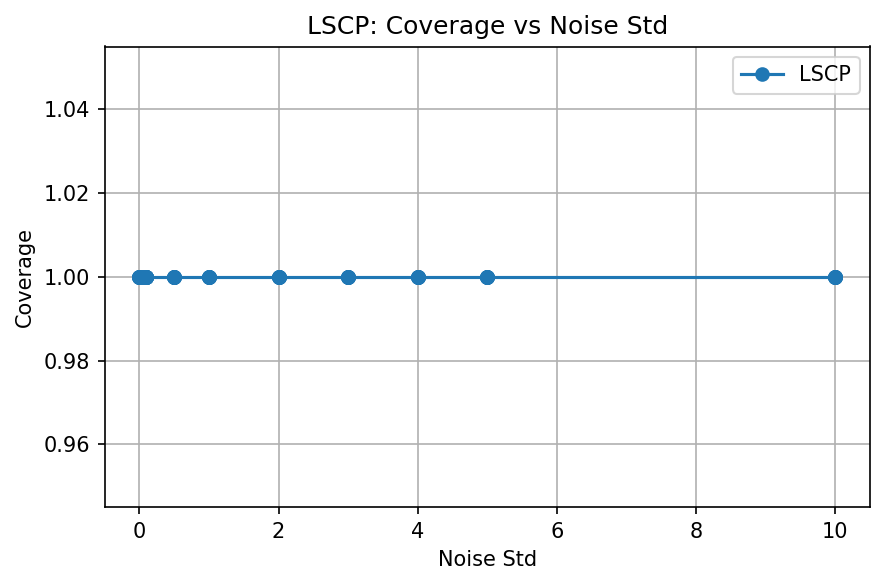

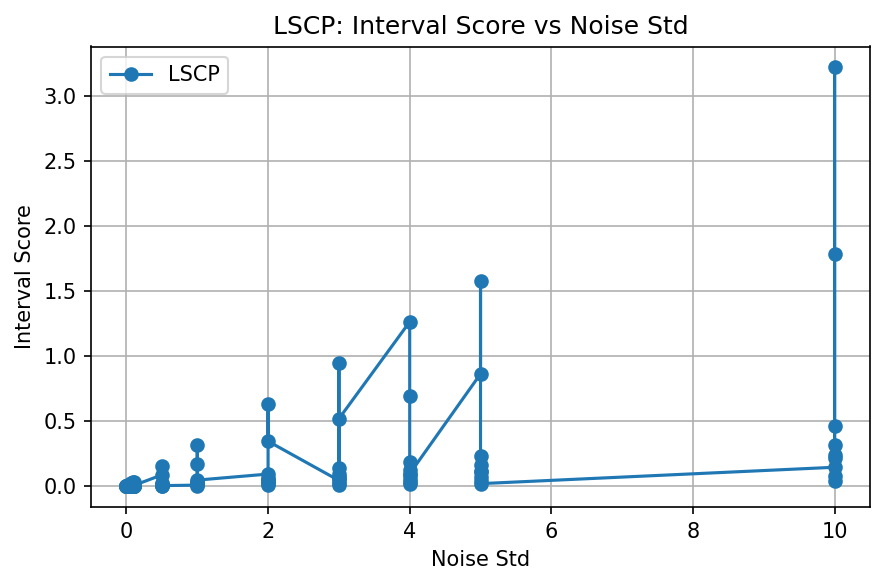

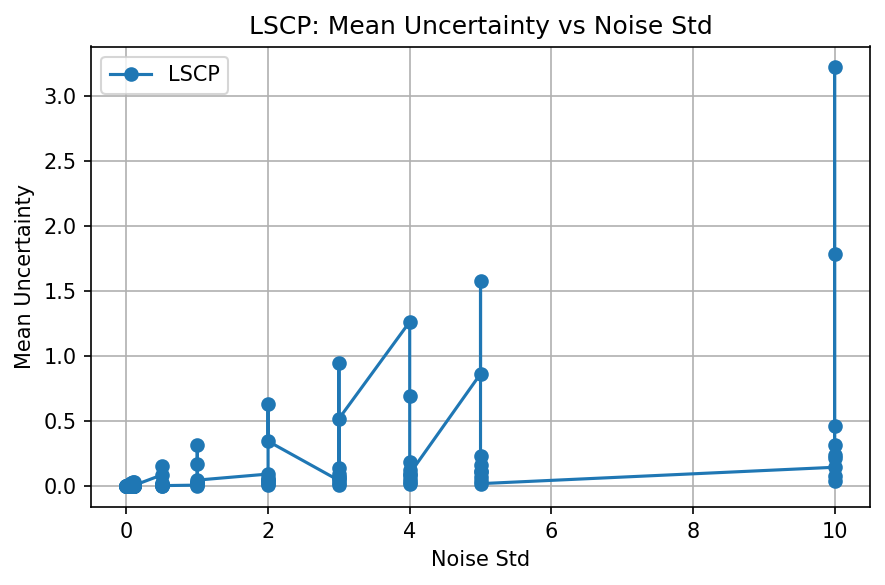

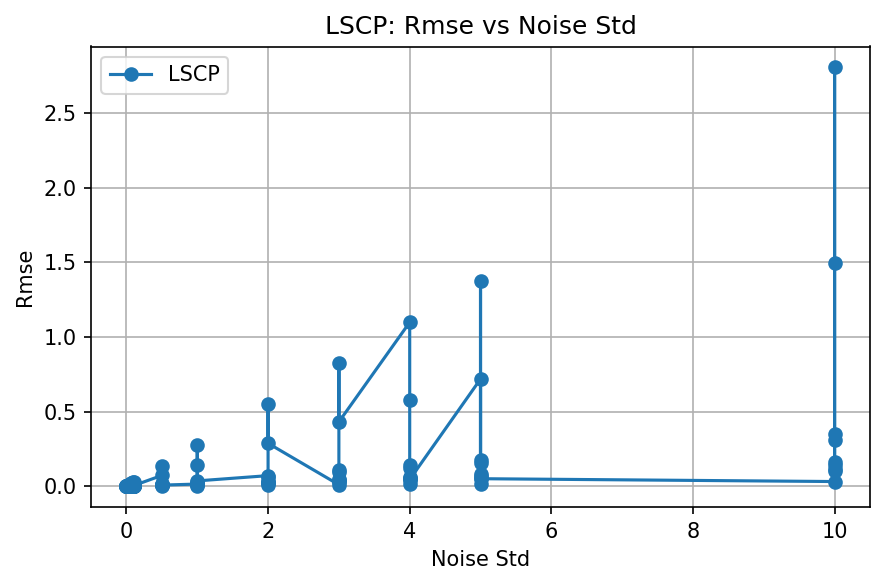

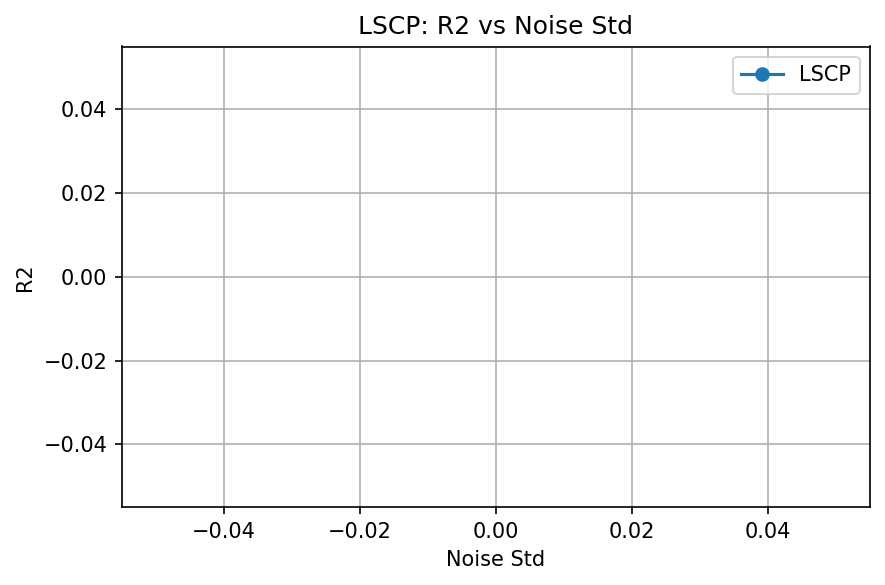

In [ ]:
results_lscp = batch_run_lscp(


    noise_std_list=[0,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.5,1,2,3,4,5,10],
    noise_sigma_list=[0.1,0.5,1,1.5,2,2.5,3,5,10],


    grid_size=100,
    base_X_coords=X_coords,
    X1=X1,
    X2=X2,
    true_y=true_y,
    loc_val=loc_val,
    y_val=y_val,
    df_coord_to_feat=df_coord_to_feat,
    create_coord_noise_df=create_coord_noise_df,
    biased_model_predict=biased_model_predict,
    k_list_lscp=[5, 8, 10, 15, 20],
    alpha=0.1,
    coverage_threshold=0.9,
    save_prefix="lscp_batch",
    feature_space_noise=True,
    sample_rate=0.0001  # ✅ 抽1%数据加速
)

save_and_plot_lscp_results(
    results_df=results_lscp,
    save_prefix="lscp_batch",
    save_dir="/content/drive/MyDrive/Research/0_GeoCP_with_geosimilarity/simulation study",  # ✅ 指定保存目录
    x_axis="noise_std",
    fixed_value=None
)



In [ ]:
results_lscp

,noise_sigma,noise_std,method,coverage,interval_score,mean_uncertainty,rmse,r2,nrmse,best_k
0,0.1,0.00,LSCP,1.0,0.000001,0.000000,0.000000,NaN,NaN,5
1,0.1,0.01,LSCP,1.0,0.003160,0.003160,0.002745,NaN,0.125015,20
2,0.1,0.02,LSCP,1.0,0.006319,0.006319,0.005491,NaN,0.125015,20
3,0.1,0.03,LSCP,1.0,0.009479,0.009479,0.008236,NaN,0.125015,20
4,0.1,0.04,LSCP,1.0,0.012639,0.012639,0.010981,NaN,0.125015,20
...,...,...,...,...,...,...,...,...,...,...
157,10.0,2.00,LSCP,1.0,0.007710,0.007710,0.019951,NaN,0.453251,20
158,10.0,3.00,LSCP,1.0,0.011565,0.011565,0.029926,NaN,0.453251,20
159,10.0,4.00,LSCP,1.0,0.015420,0.015420,0.039902,NaN,0.453251,20
160,10.0,5.00,LSCP,1.0,0.019276,0.019276,0.049877,NaN,0.453251,20
